In [26]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Reading Transformed Stock Data for Portfolio

In [27]:
# Reading Log Returns for Each Asset and the Interest Rates for the Credit

# STOCK DATA
portfolio_df = pd.read_csv("_portfolio_returns.csv", index_col=["Date"]).drop(columns=["EUR_USD"])
# portfolio_df = portfolio_df.drop(columns=["EUR_USD"]) # For now just drop, need answer to Q1
# portfolio_df = portfolio_df*(-1)      # Converting into Loss Distribution. instead of P/L, IT IS THAT SIMPLE RIGHT?

# Reading Rates for Credit
euribor = pd.read_csv("_EURIBOR_monthly_rates.csv", index_col=["Date"])
# ...       # Nothing for now, need answer to Q2

# Declaring weights for portfolio construction, DON'T FORGET TO UPDAtE ONCE CREDIT IS ADDED
PORTFOLIO_WEIGHTS= np.array([0.15, 0.2, 0.15, 0.15, 0.15, 0.2])     # If we short something we can get more cash to invest
ROLLING_WINDOW = 258                                                # Trading days per year for our portfolio (can be multiple years too)

## QUESTIONS: 
### SHOULD WE JUST CONVERT EACH DAY TO EURO RETURNS? BECAUSE WE ARE EXPOSED EVERY DAY? THAT IS THE POINT RIGHT? OR ONLY ON BUY/SELL (START/END) DAYS AND COMPARE? IF EVERYDAY, SHOULD WE COMPARE WITH SAME PORTFOLIO BUT ASSUME EXCHANGE RATE IS FIXED TO SHOW THE LOWER/HIGHER VOLATILITY. - Covered 10 Apr, in the book too. Just add more weights or soemthing.
### I HAVE NO IDEA HOW TO CALCULATE RETURNS/LOSES ON CREDIT. HOW IS IT DONE GIVEN RATES? ON DAILY BASIS?    -   Will be covered on 15th
### JUST MULTIPLY BY -1 TO GET LOSS DISTRIBUTION. IT IS JUST FOR THE CONVENTION RIGHT? NO REAL DIFFERENCE?  - Yes
### QQPLOT MUST HAVE A LINE=Q, WHICH GOES THROUGH QUANTILES, NOT JUST 45 DEGREEES? IT DOES NOT MAKE MUCH SENSE, AS IT IS OBVIOUSLY IS NOT STANDARD NORMAL DISTRIBUTION, CORRECT? OR SHOULD WE STANDARDIZE THE RETURNS FOR QQPLOT?           - Yes
### DO WE CALCULATE RETURNS PROPERLY? WE USE LOG RETURNS.                           - Yes
### SHOULD WE JUST DROP ZEROS FROM NON-TRADING DAYS FOR THE VISUALIZATION? SHOULD WE IMPUTE THEM WITH  NON_EXISTENT RETURNS IN BETWEEN?     - Yes, drop the weekends because we do nto open office on these days, they distort portfolio returns more, rather than provide.
### IS CODE EVALUATED?      - Optionally uploaded.

### Window size is 365 because of BTC       - Use any window you want
### I think we are supposed to work with distribution of losses - Yes


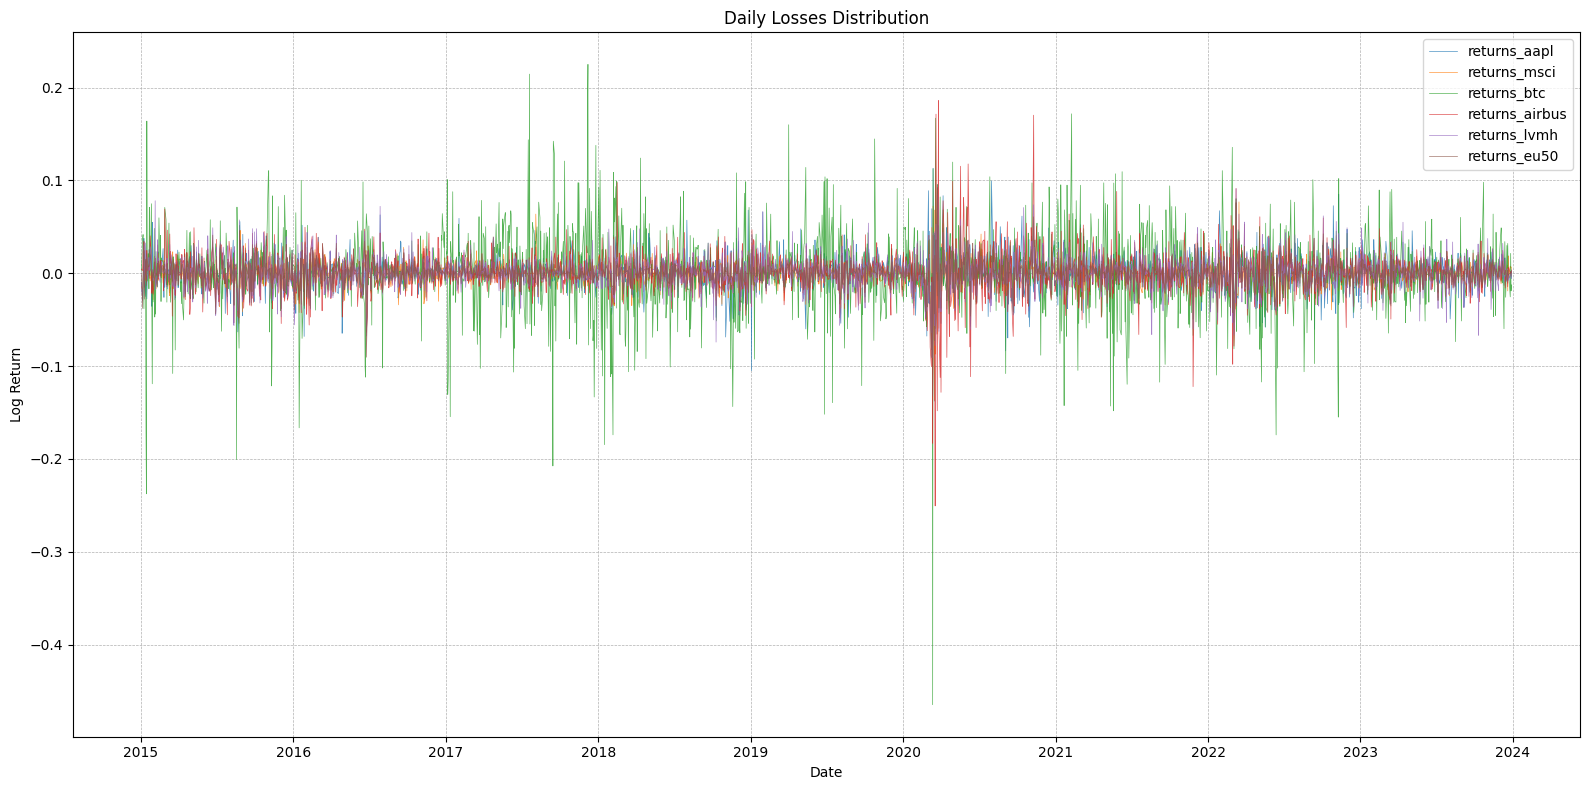

In [28]:
# Plotting
plt.figure(figsize=(16, 8))
portfolio_df.index = pd.to_datetime(portfolio_df.index)       # Making sure matplotlib recognizes the datetime index

for column in portfolio_df.columns:
    plt.plot(portfolio_df.index, portfolio_df[column], lw=.5, alpha=0.8, label=column)

# Setting the x-axis to only show years
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.legend()
plt.title('Daily Losses Distribution')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.grid(True, linestyle='--', linewidth=0.5)
plt.tight_layout()

plt.show()


# Value-at-Risk and Expected Shortfall with Variance-CoVariance method

### Functions that are necessary for all methods

In [29]:
data = portfolio_df

rolling_vol: pd.DataFrame = data.rolling(window = ROLLING_WINDOW).std(ddof = 0).dropna()

In [30]:
from typing import Callable, Any

def PortRet(*, data: pd.DataFrame, weights: np.array) -> pd.DataFrame:
    return data @ weights

def VCV(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """
    rolling_vol: pd.DataFrame = data.rolling(window = window_size).std(ddof = 0).dropna()
    portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights

    portfolio_VaR = pd.DataFrame(portfolio_volatility, index = rolling_vol.index, columns = ['Vol'])
    portfolio_VaR['VaR'] = portfolio_volatility * dist(alpha, **kwargs)
    return portfolio_VaR

def VCE(Vol: Any, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate the expected shortfall
    """
    alpha = 1 - alpha
    match dist:
        case stats.norm:
            q: float = stats.norm.isf(alpha)
            p: float = stats.norm.pdf(q)
            return -1 * Vol * p / (1 - alpha)
        case stats.t:
            df: int | float = kwargs.get('df', 4)
            q: float = stats.t.isf(alpha, df = df)
            p: float = stats.t.pdf(q, df = df)
            return -1 * Vol * ((df + (q ** 2)) / (df - 1)) * p / (1 - alpha)
        case _:
            raise NotImplementedError()    


In [31]:
def volatility(omega, alpha, beta, x):
    # this function is the main volatility filter needed to obtain the results while estimating

    T = len(x)

    # Filter Volatility
    sig     = np.zeros(T)
    sig[0]  = np.var(x[:50], ddof = 0); #initialize volatility at unconditional variance

    # loop iteratively over the indices and define the volatilities in that way
    for t in range(0,T-1):
        sig[t+1] = omega + alpha *  x[t]**2 + beta * sig[t]

    return sig ** .5

def VCV_ES_GARCH(data: pd.DataFrame, weights: np.array):
    CM: np.matrix | pd.DataFrame = data.corr()
    n: int = CM.shape[0]
    W = weights.reshape((n, 1)) * weights.reshape((1,6))
    CMU: np.matrix = CM * W
    
    vol_df = data * 0
    for asset in data.columns:
        x = data[asset]
        alpha, beta = .05, .93
        omega = np.var(x) * (1 - alpha - beta)
        vol_df[asset] = volatility(omega, alpha, beta, x)
    
    vol = []
    Sigm = vol_df.values
    for row in Sigm:
        vol.append(row @ CMU @ row)

    return np.array(vol) ** .5

def VCVG(vol, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """
    return vol * dist(alpha, **kwargs)

In [32]:
portfolio_sliced = portfolio_df[250:]
GARCH = VCV_ES_GARCH(portfolio_sliced, weights = PORTFOLIO_WEIGHTS)

In [33]:
VaR_data_norm = VCV(portfolio_df, window_size = ROLLING_WINDOW, port_weights = PORTFOLIO_WEIGHTS, alpha = .05, dist = stats.norm.ppf)
VaR_data_t_df4 = VCV(portfolio_df, window_size = ROLLING_WINDOW, port_weights = PORTFOLIO_WEIGHTS, alpha = .05, dist = stats.t.ppf, df = 4)
VaR_data_t_df5 = VCV(portfolio_df, window_size = ROLLING_WINDOW, port_weights = PORTFOLIO_WEIGHTS, alpha = .05, dist = stats.t.ppf, df = 5)
VaR_data_t_df6 = VCV(portfolio_df, window_size = ROLLING_WINDOW, port_weights = PORTFOLIO_WEIGHTS, alpha = .05, dist = stats.t.ppf, df = 6)
VaR_data_GARCH = VCVG(GARCH, alpha = .05, dist = stats.norm.ppf)

In [34]:
ES_data_norm = VCE(VaR_data_norm.Vol, alpha = .05, dist = stats.norm)
ES_data_t_df4 = VCE(VaR_data_t_df4.Vol, alpha = .05, dist = stats.t, df = 4)
ES_data_t_df5 = VCE(VaR_data_t_df5.Vol, alpha = .05, dist = stats.t, df = 5)
ES_data_t_df6 = VCE(VaR_data_t_df6.Vol, alpha = .05, dist = stats.t, df = 6)
ES_data_GARCH = VCE(GARCH, alpha = .05, dist = stats.norm)

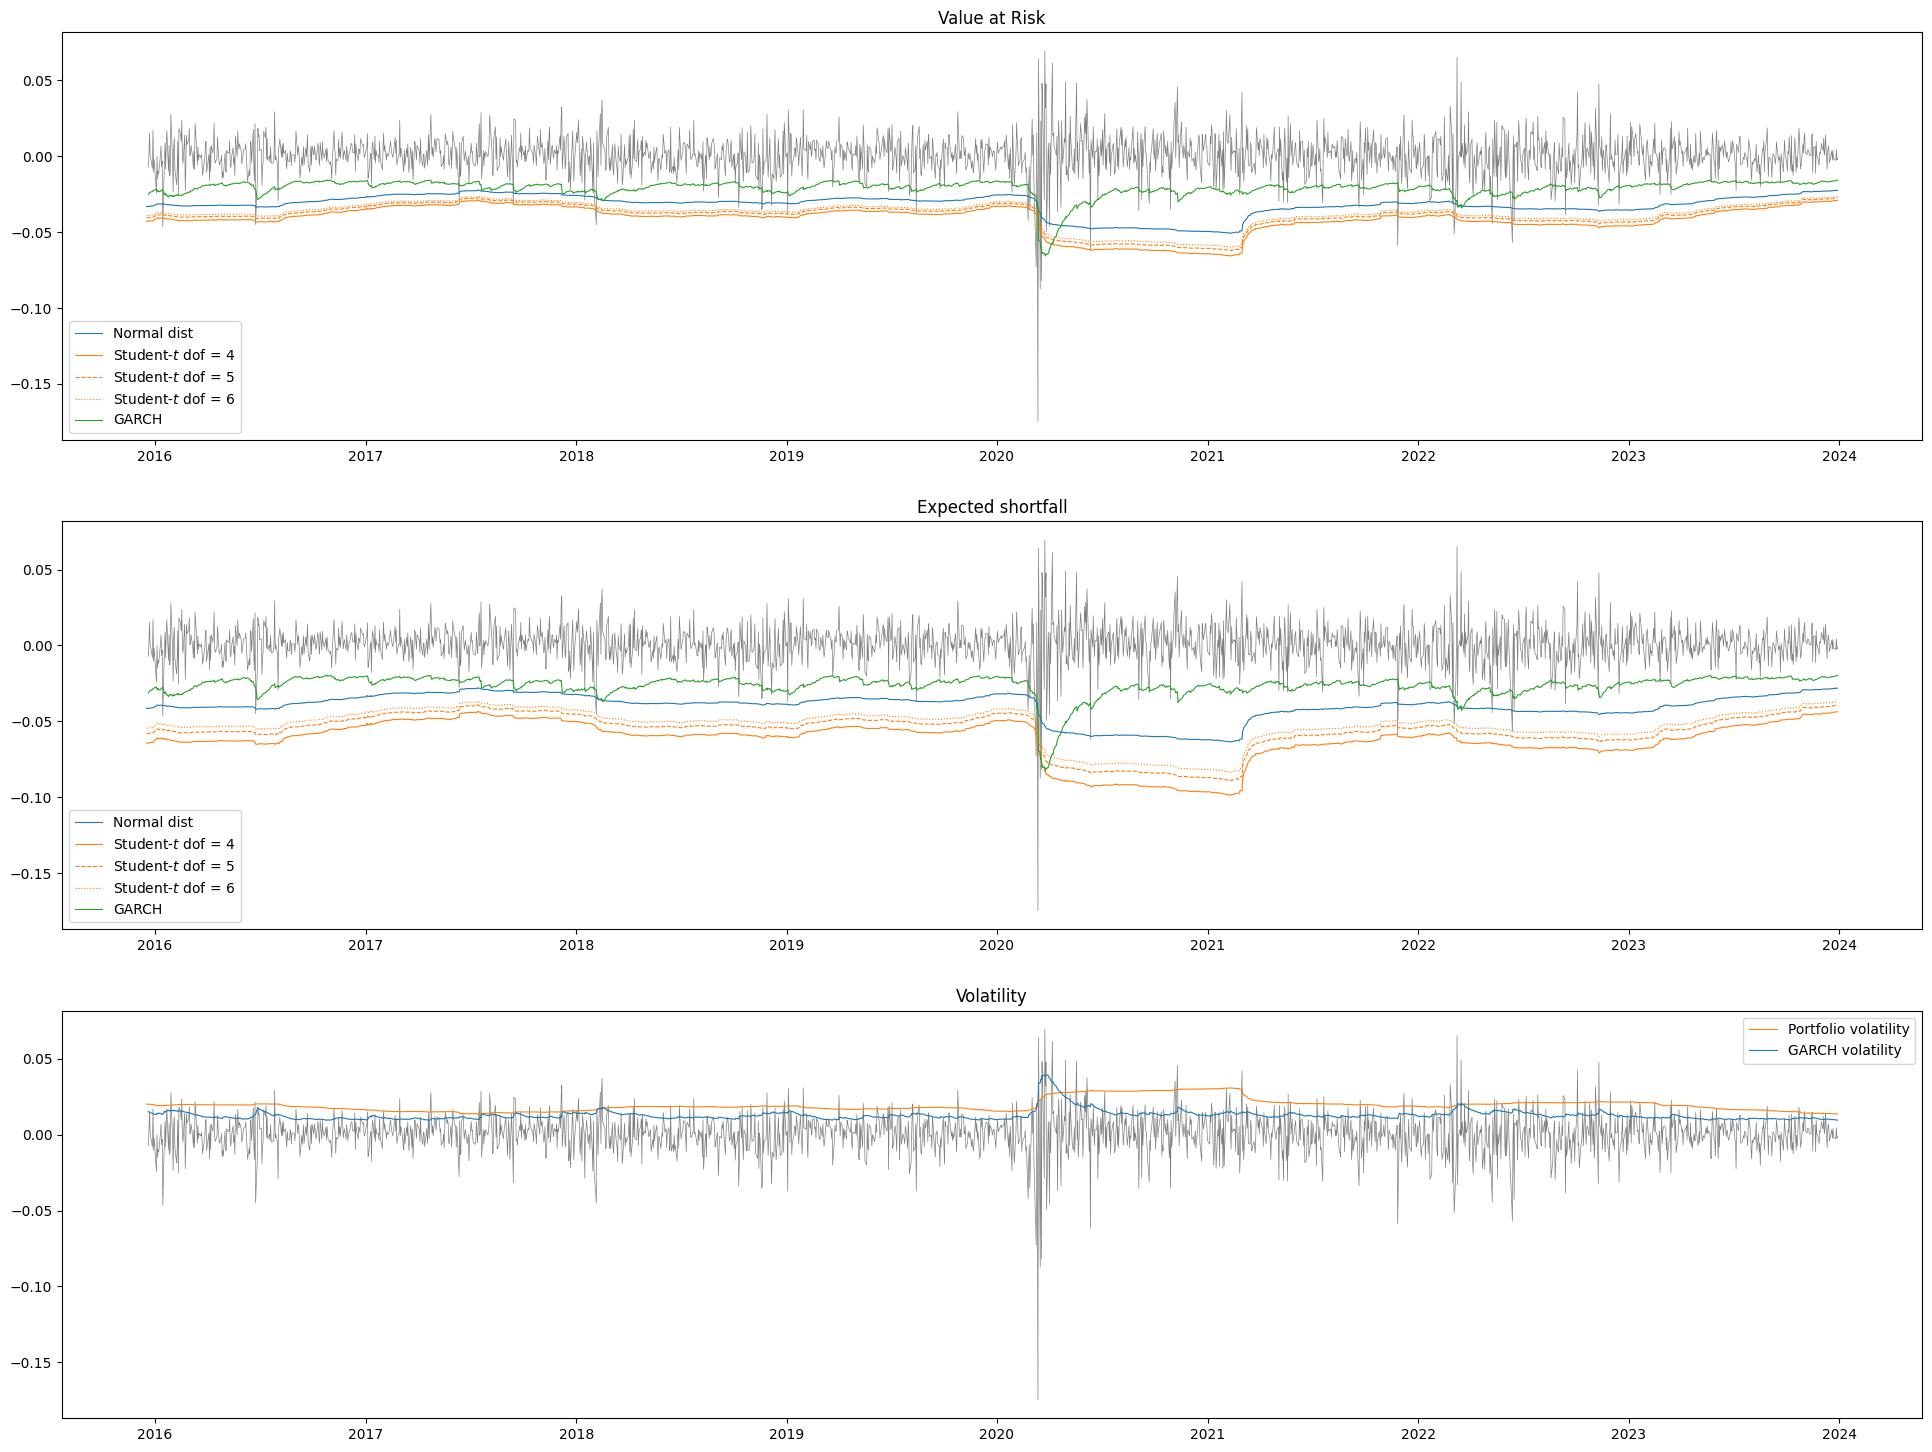

In [35]:
fig, axs = plt.subplots(3, 1, figsize = (24, 18))
axs[1].set_title('Expected shortfall')
axs[1].plot(PortRet(data = portfolio_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[1].plot(ES_data_norm, label = 'Normal dist', lw = .8)
axs[1].plot(ES_data_t_df4, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1].plot(ES_data_t_df5, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1].plot(ES_data_t_df6, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(PortRet(data = portfolio_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[0].plot(VaR_data_norm.VaR, label = 'Normal dist', lw = .8)
axs[0].plot(VaR_data_t_df4.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0].plot(VaR_data_t_df5.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0].plot(VaR_data_t_df6.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
axs[0].plot(portfolio_sliced.index, VaR_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
axs[0].legend()

axs[2].set_title('Volatility')
axs[2].plot(PortRet(data = portfolio_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
axs[2].plot(rolling_vol.index, rolling_vol.values @ PORTFOLIO_WEIGHTS, c = 'C1', lw = .8, label = 'Portfolio volatility')
axs[2].plot(portfolio_sliced.index, GARCH, c = 'C0', lw = .8, label = 'GARCH volatility')
axs[2].legend()
plt.show()

In [36]:
def VCHS(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate VaR and ES using historic simulation
    """
    rolling_vol: pd.DataFrame = data.rolling(window = window_size).std(ddof = 0).dropna()
    portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights

    portfolio_VaR = pd.DataFrame(portfolio_volatility, index = rolling_vol.index, columns = ['Vol'])
    portfolio_VaR['Devol'] = data.loc[rolling_vol.index] / rolling_vol

    VaR = portfolio_VaR['Devol'].rolling(window = window_size).quantile(1 - alpha).dropna()
    ES  = portfolio_VaR['Devol'].rolling(window = window_size).quantile(1 - alpha).dropna()

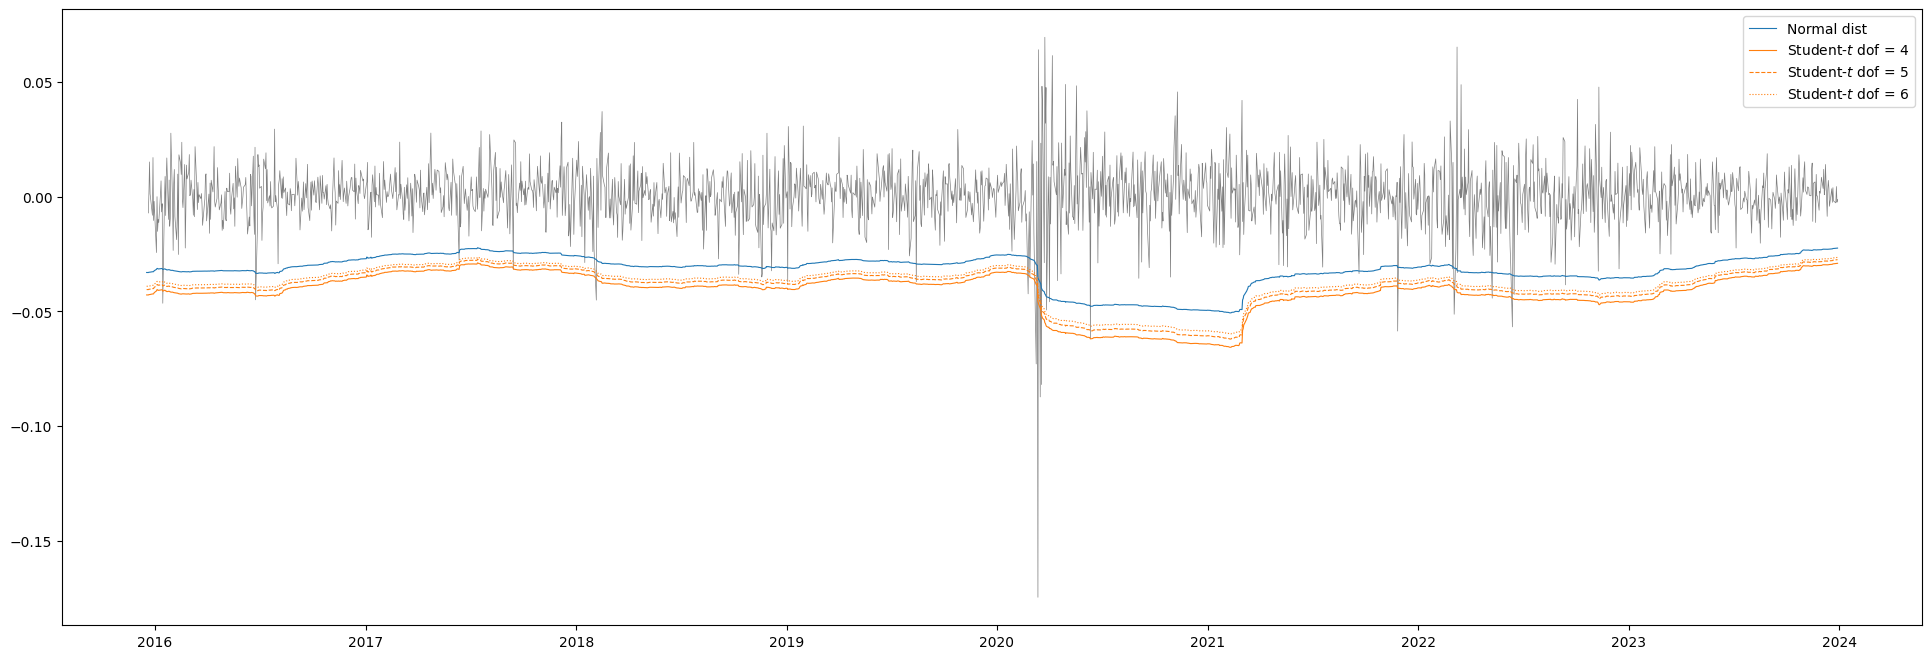

In [37]:
# Is this plot just the earlier version of the plot above
plt.rcParams['figure.figsize'] = (24, 8)
plt.plot(PortRet(data = portfolio_sliced, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
plt.plot(VaR_data_norm.VaR, label = 'Normal dist', lw = .8)
plt.plot(VaR_data_t_df4.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
plt.plot(VaR_data_t_df5.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
plt.plot(VaR_data_t_df6.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
plt.legend()
plt.show()

### Old Code

In [38]:
def calculate_var_normal(annual_volatility, mean_return, z_score):
    """
    Calculate the Value at Risk (VaR) using the Normal distribution method.

    Parameters:
    - annual_volatility (float): The annual volatility of the portfolio or asset.
    - mean_return (float): The mean return of the portfolio or asset.
    - z_score (float): The Z-score corresponding to the desired confidence level.

    Returns:
    - float: The calculated VaR.
    """
    return mean_return + z_score * annual_volatility

def calculate_var_student_t(annual_volatility, mean_return, t_critical_value, degrees_of_freedom):
    """
    Calculate the Value at Risk (VaR) using Student's T-distribution method.

    Parameters:
    - annual_volatility (float): The annual volatility of the portfolio or asset.
    - mean_return (float): The mean return of the portfolio or asset.
    - t_critical_value (float): The critical value from the T-distribution corresponding to the desired confidence level.
    - degrees_of_freedom (int): The degrees of freedom for the T-distribution.

    Returns:
    - float: The calculated VaR adjusted for the fat tails of the T-distribution.
    """
    adjusted_volatility = annual_volatility / np.sqrt(degrees_of_freedom / (degrees_of_freedom - 2))
    return mean_return + t_critical_value * adjusted_volatility

def calculate_es_normal(annual_volatility, mean_return, z_score, confidence_level):
    """
    Calculate the Expected Shortfall (ES) using the Normal distribution method.

    Parameters:
    - annual_volatility (float): The annual volatility of the portfolio or asset.
    - mean_return (float): The mean return of the portfolio or asset.
    - z_score (float): The Z-score corresponding to the desired confidence level.
    - confidence_level (float): The confidence level as a decimal (e.g., 0.95 for 95%).

    Returns:
    - float: The calculated ES.
    """
    density_at_z = stats.norm.pdf(z_score)
    return (density_at_z / (1 - confidence_level)) * annual_volatility + mean_return

def calculate_es_student_t(annual_volatility, mean_return, t_critical_value, degrees_of_freedom, confidence_level):
    """
    Calculate the Expected Shortfall (ES) using Student's T-distribution method.

    Parameters:
    - annual_volatility (float): The annual volatility of the portfolio or asset.
    - mean_return (float): The mean return of the portfolio or asset.
    - t_critical_value (float): The critical value from the T-distribution corresponding to the desired confidence level.
    - degrees_of_freedom (int): The degrees of freedom for the T-distribution.
    - confidence_level (float): The confidence level as a decimal (e.g., 0.95 for 95%).

    Returns:
    - float: The calculated ES adjusted for the fat tails of the T-distribution.
    """
    adjusted_volatility = annual_volatility / np.sqrt(degrees_of_freedom / (degrees_of_freedom - 2))
    density_at_t = stats.t.pdf(t_critical_value, degrees_of_freedom)
    return (density_at_t / (1 - confidence_level)) * ((degrees_of_freedom + t_critical_value**2) / (degrees_of_freedom - 1)) * adjusted_volatility + mean_return

def calculate_portfolio_risk_metrics(weight_vector, log_losses, distribution_method="Normal", degrees_of_freedom=1):
    """
    Calculate Value at Risk (VaR) and Expected Shortfall (ES) for a portfolio using either
    Normal or Student's t-distribution methods.

    Parameters:
    - weight_vector (np.array): The weight of each asset in the portfolio.
    - log_losses (np.array): Logarithmic losses of the assets in the portfolio.
    - distribution_method (str): Specifies the distribution method to use for calculating VaR and ES. 
      Accepts "Normal" for Normal distribution or "Student" for Student's t-distribution.
    - degrees_of_freedom (int): The degrees of freedom for the Student's t-distribution. 
      This parameter is ignored if distribution_method is "Normal".

    Returns:
    - tuple: A tuple containing the calculated VaR and ES values at 97.5% and 99% confidence levels (Four Floats Overall: VaR_975, VaR_99, ES_975, ES_99).
    """

    # Estimate Variance-Covariance matrix of portfolio returns
    covariance_matrix = np.cov(log_losses, rowvar=False)

    # Calculate portfolio volatility
    portfolio_volatility = np.sqrt(weight_vector.T @ covariance_matrix @ weight_vector)
    # Assuming mean return (mu) is zero for a short horizon
    mean_return = 0

    # Initialize variables for clarity
    VaR_975, VaR_99, ES_975, ES_99 = 0, 0, 0, 0

    # Calculate VaR and ES based on the specified distribution method
    if distribution_method == "Normal":
        # Z-scores for 97.5% and 99% confidence intervals for Normal distribution
        z_975, z_99 = 1.96, 2.33
        VaR_975 = calculate_var_normal(portfolio_volatility, mean_return, z_975)
        VaR_99 = calculate_var_normal(portfolio_volatility, mean_return, z_99)
        ES_975 = calculate_es_normal(portfolio_volatility, mean_return, z_975, 0.975)
        ES_99 = calculate_es_normal(portfolio_volatility, mean_return, z_99, 0.99)
    elif distribution_method == "Student":
        # Critical t-values for 97.5% and 99% confidence intervals for Student's t-distribution
        tTest_ES_975 = stats.t.ppf(0.975, degrees_of_freedom)
        t_99 = stats.t.ppf(0.99, degrees_of_freedom)
        VaR_975 = calculate_var_student_t(portfolio_volatility, mean_return, tTest_ES_975, degrees_of_freedom)
        VaR_99 = calculate_var_student_t(portfolio_volatility, mean_return, t_99, degrees_of_freedom)
        ES_975 = calculate_es_student_t(portfolio_volatility, mean_return, tTest_ES_975, degrees_of_freedom, 0.975)
        ES_99 = calculate_es_student_t(portfolio_volatility, mean_return, t_99, degrees_of_freedom, 0.99)

    return VaR_975, VaR_99, ES_975, ES_99


## Normal Distribution Assumption

In [39]:
portfolio = -portfolio_df.to_numpy()
portfolio_weighted = -portfolio_df.dot(PORTFOLIO_WEIGHTS)

In [40]:
# CHANGE THIS THING TO USE WITH DAAN'S FUNCTIONS
N = 6               # Number of Assets in the Portfolio
T = len(portfolio)  # Number of Observations

# Calculating VaR/ES
VarCovN_VaR_975 = np.zeros(T-ROLLING_WINDOW)
VarCovN_VaR_99 = np.zeros(T-ROLLING_WINDOW)
VarCovN_ES_975 = np.zeros(T-ROLLING_WINDOW)
VarCovN_ES_99 = np.zeros(T-ROLLING_WINDOW)
for i in range(T-ROLLING_WINDOW):
  (VarCovN_VaR_975[i], VarCovN_VaR_99[i], VarCovN_ES_975[i], VarCovN_ES_99[i]) = calculate_portfolio_risk_metrics(PORTFOLIO_WEIGHTS, portfolio[i:ROLLING_WINDOW+i,:], "Normal")

### Visualizing Normal Distribution Assumption per each Asset in the Portfolio

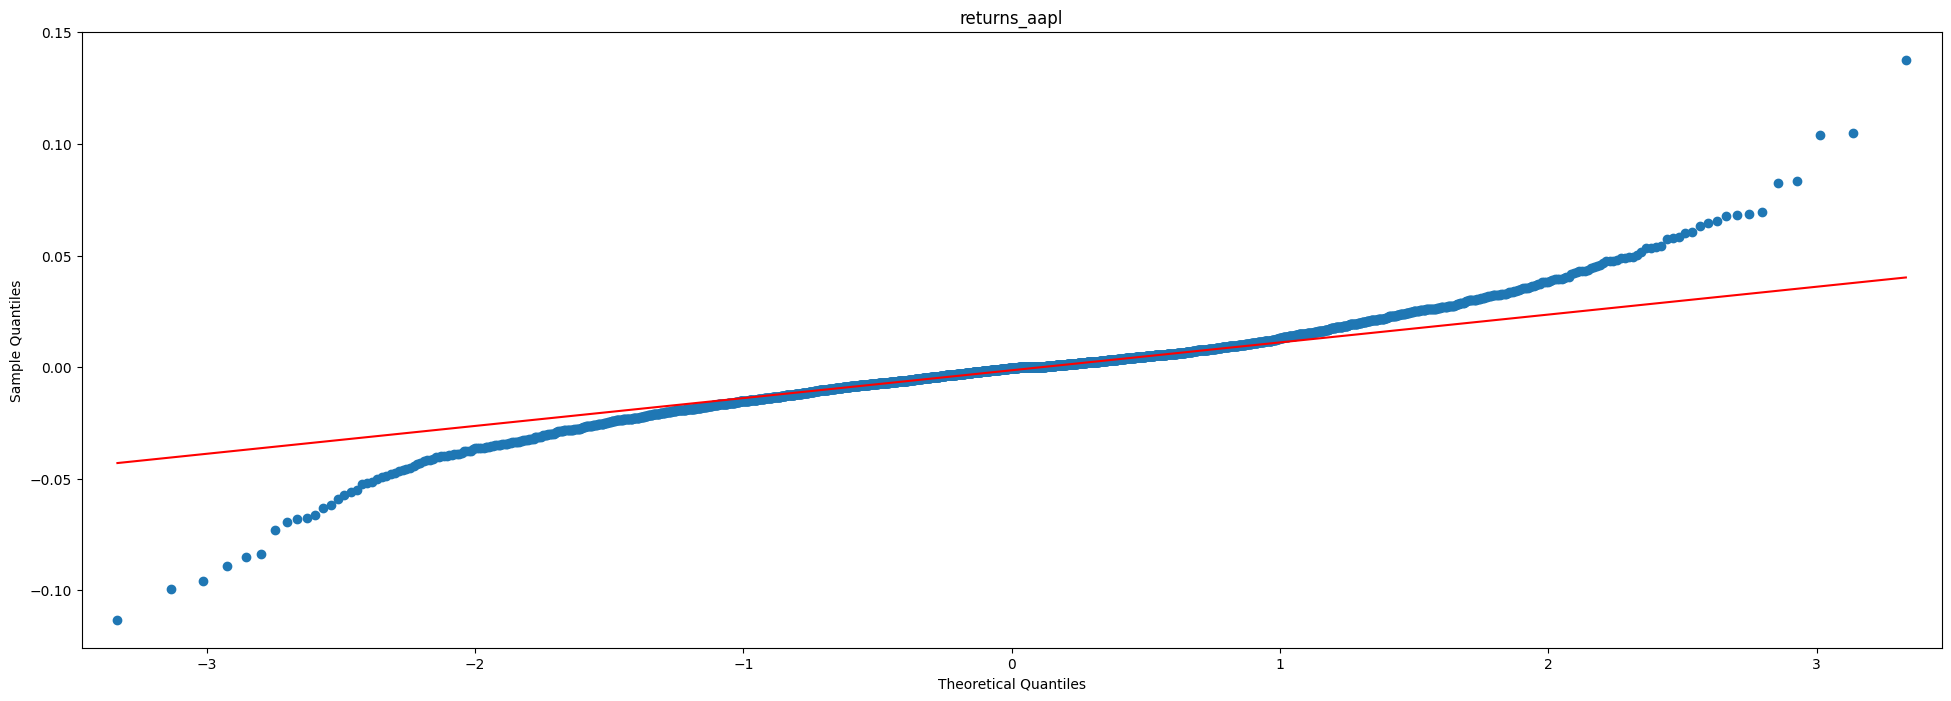

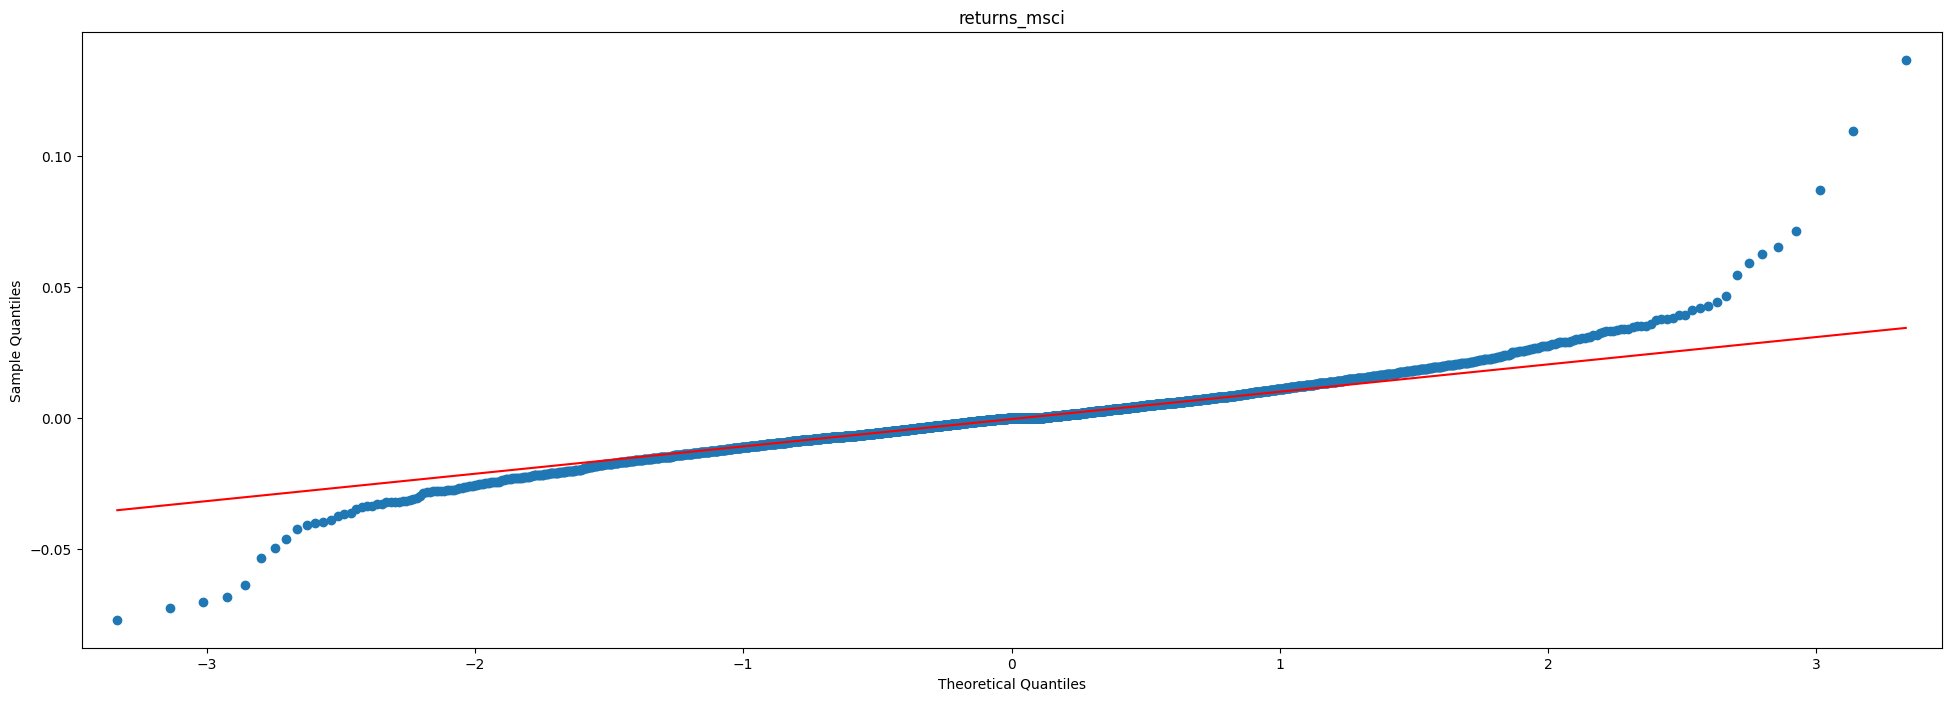

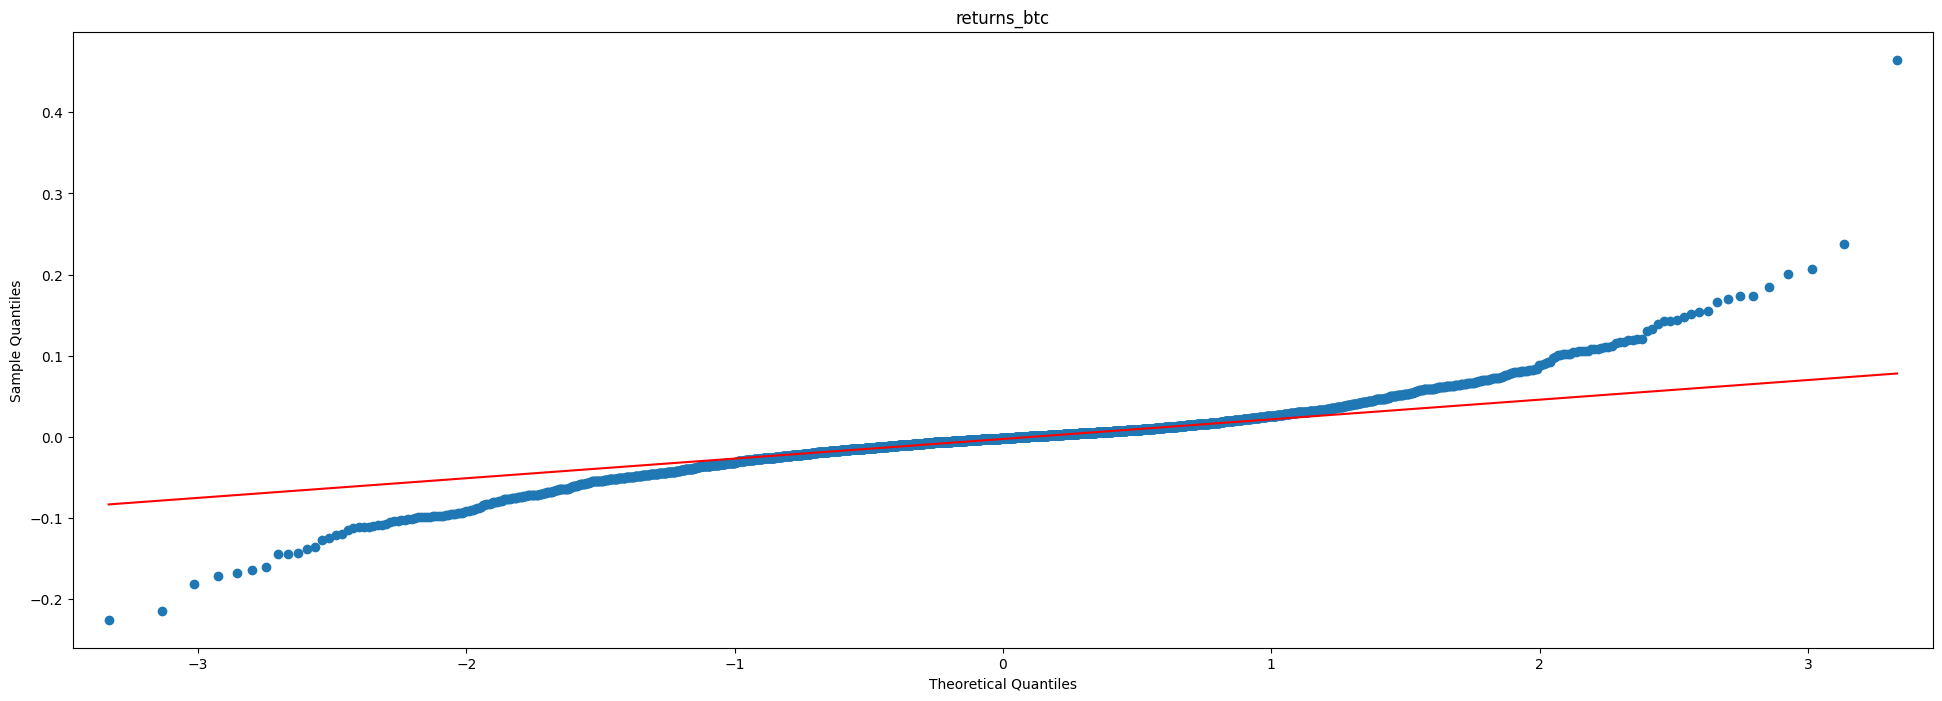

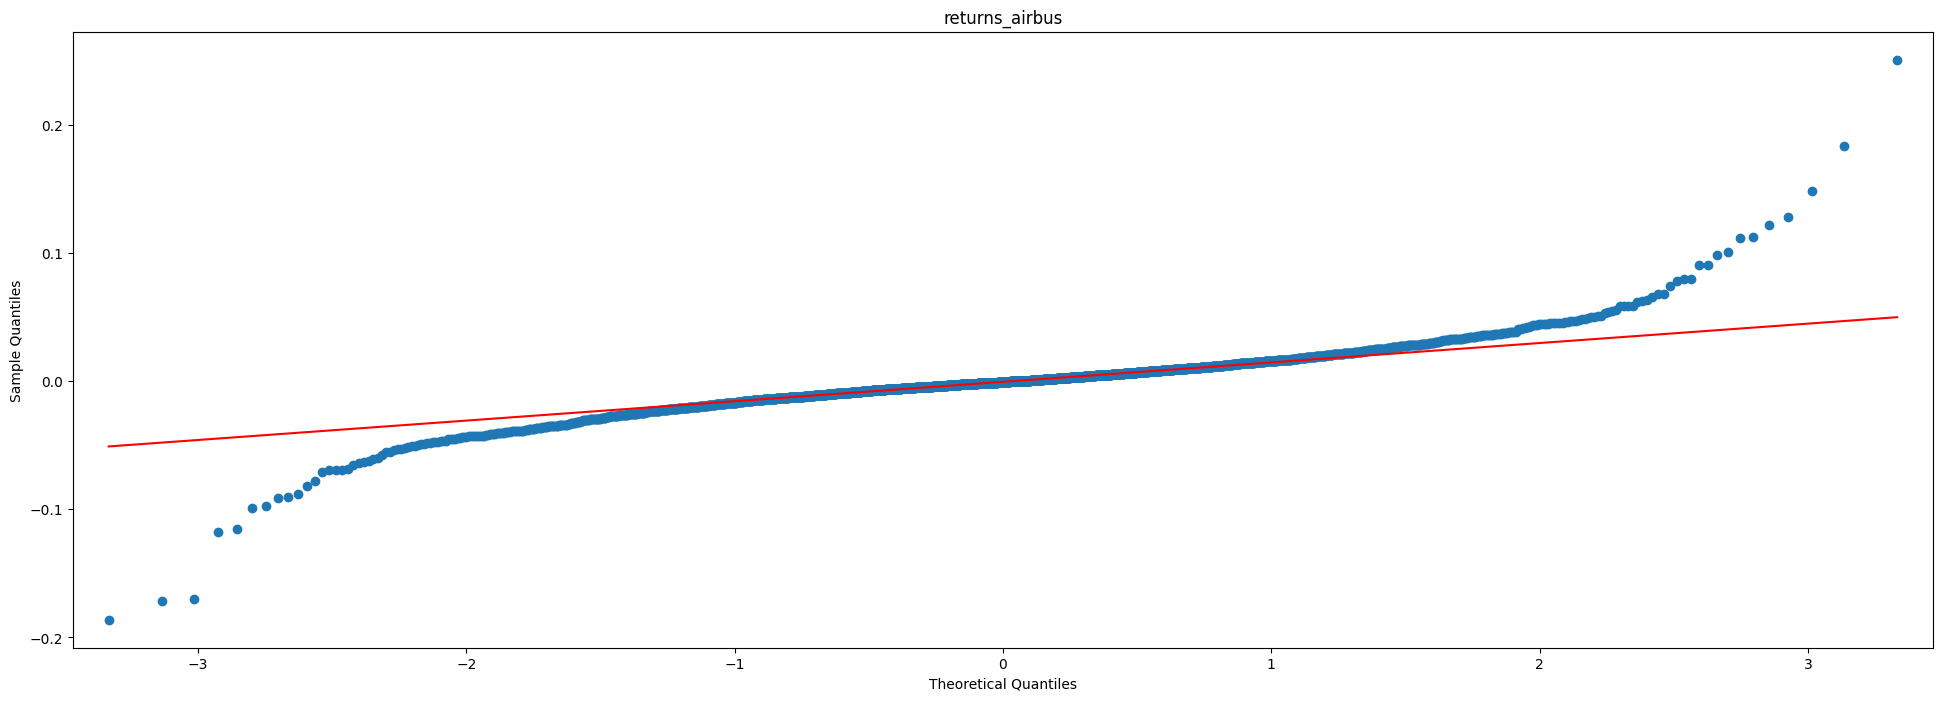

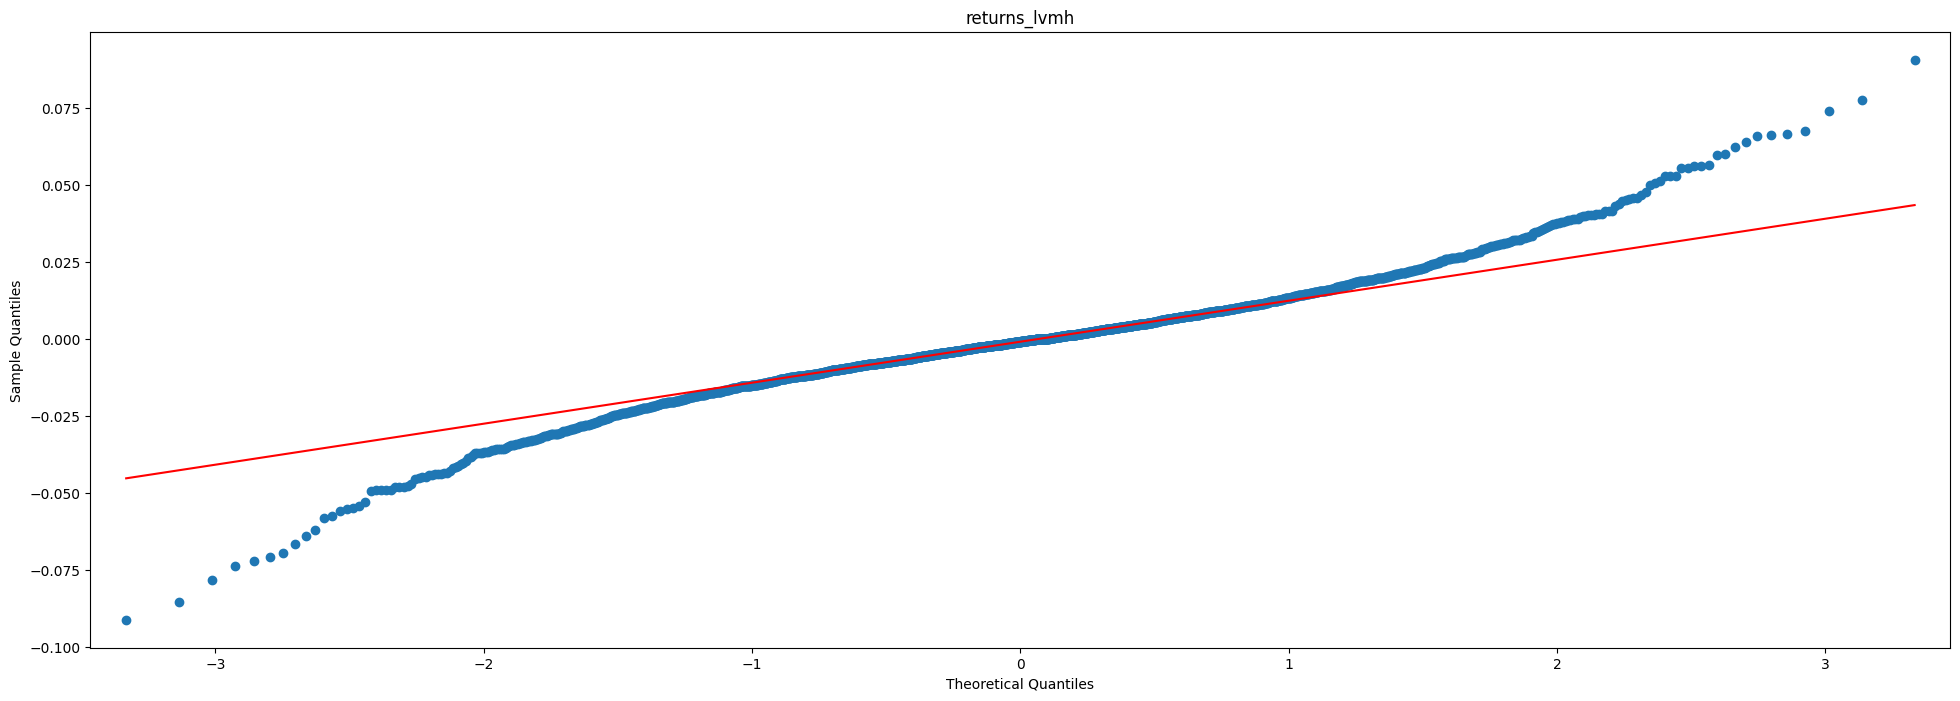

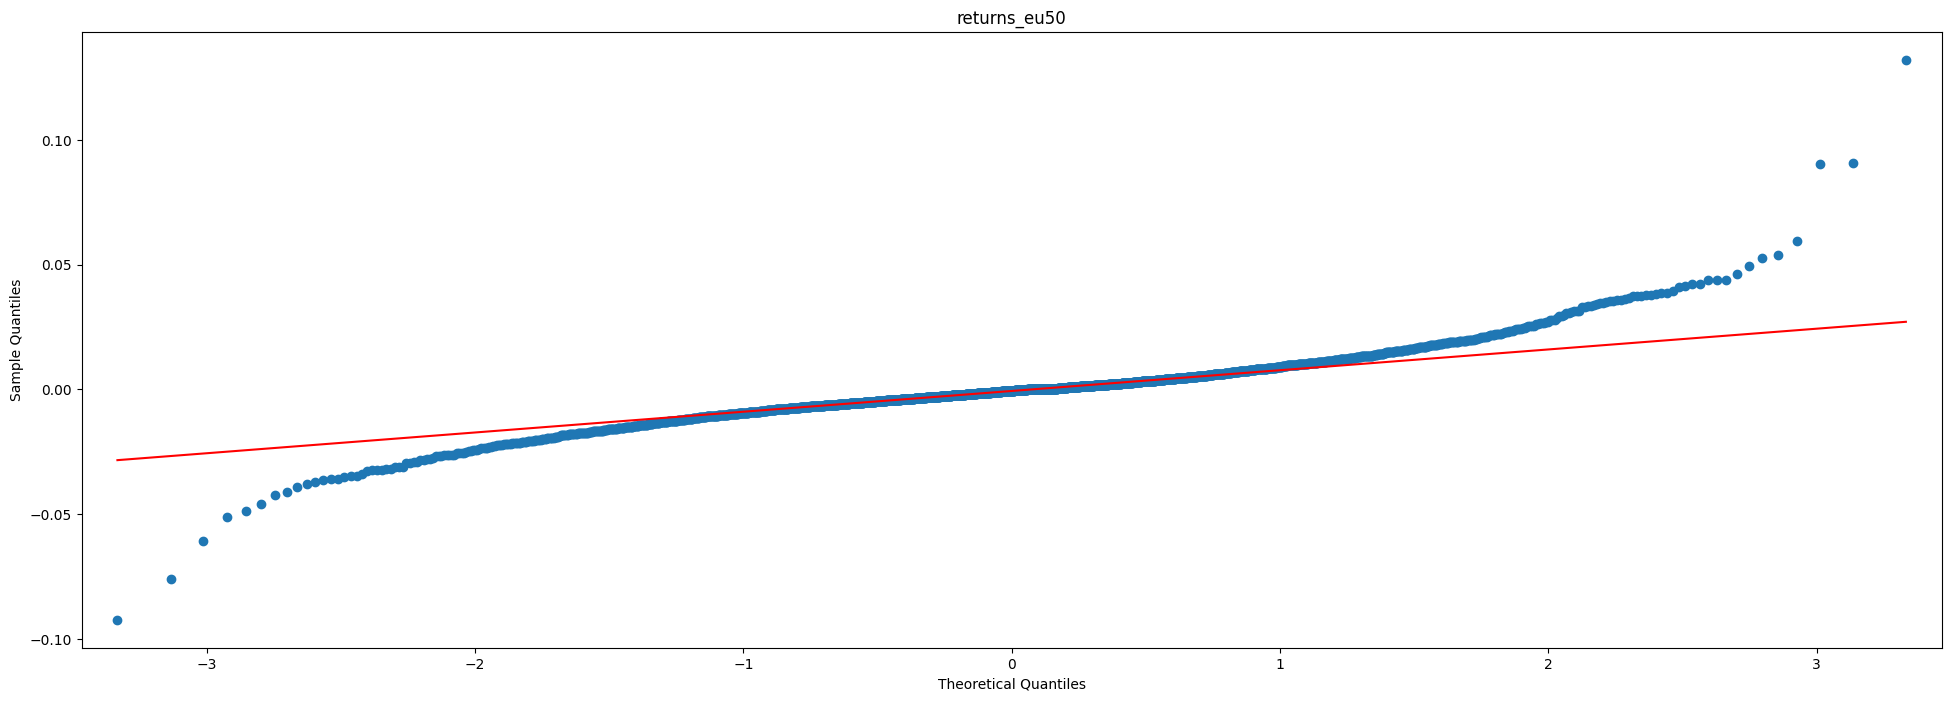

In [41]:
# QQ-Plot to see if asset returns follow normal distribution
for i in range(N):
    sm.qqplot(portfolio[:,i], line="q")     # IS LINE=Q OR LINE=R OR LINE 45? Q3
    plt.title(portfolio_df.columns[i])

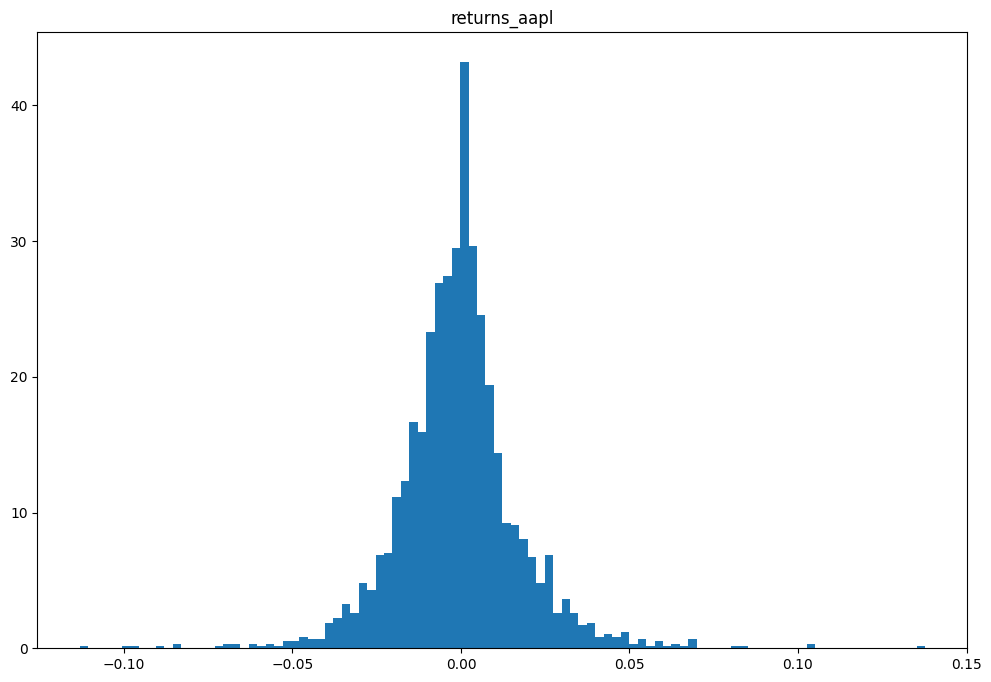

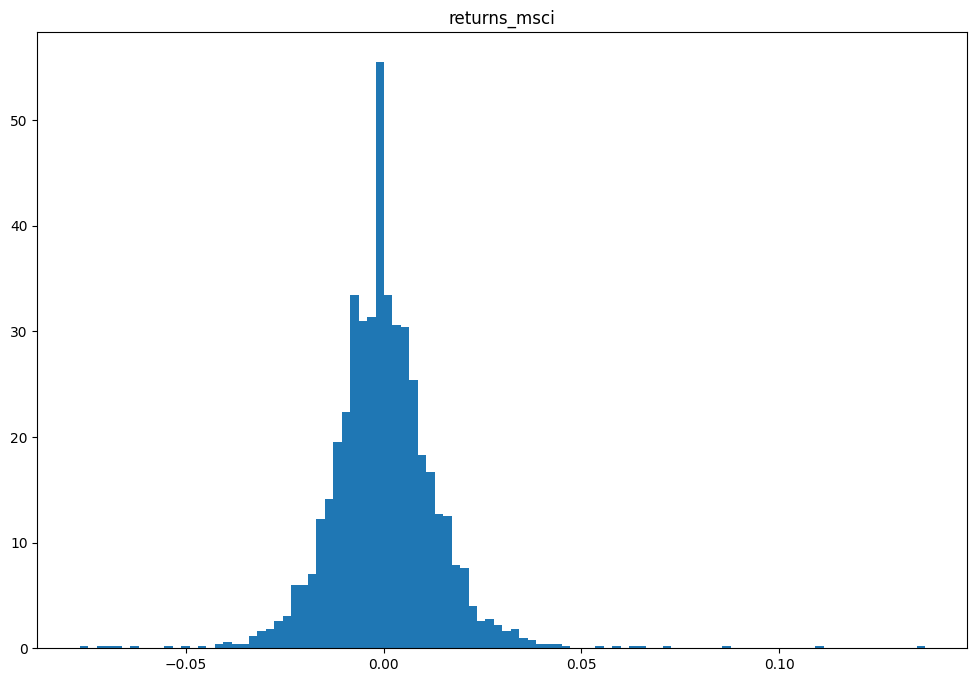

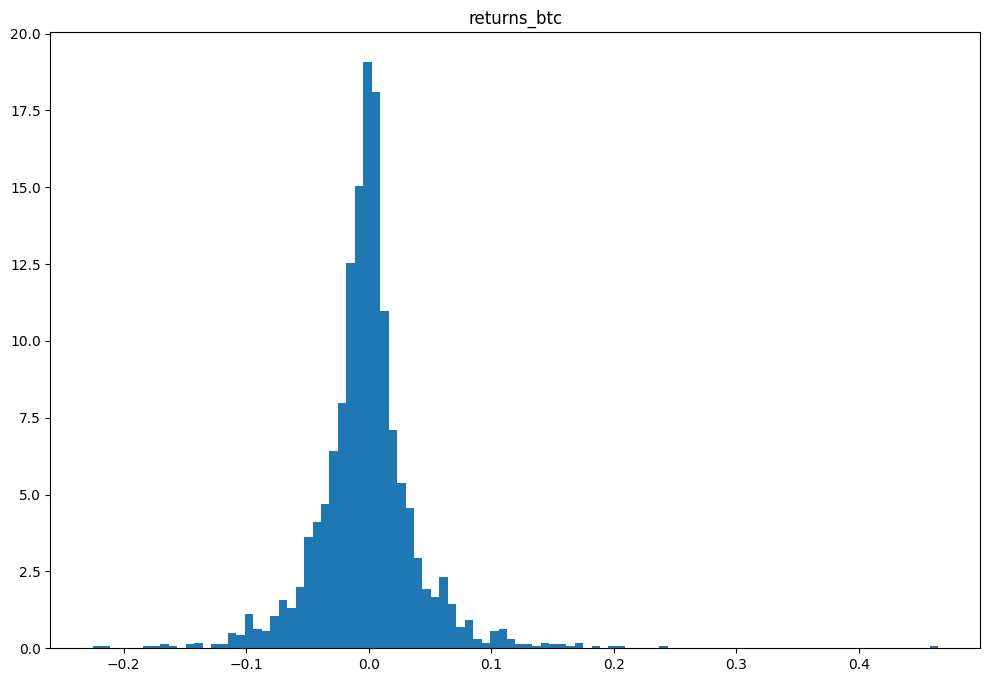

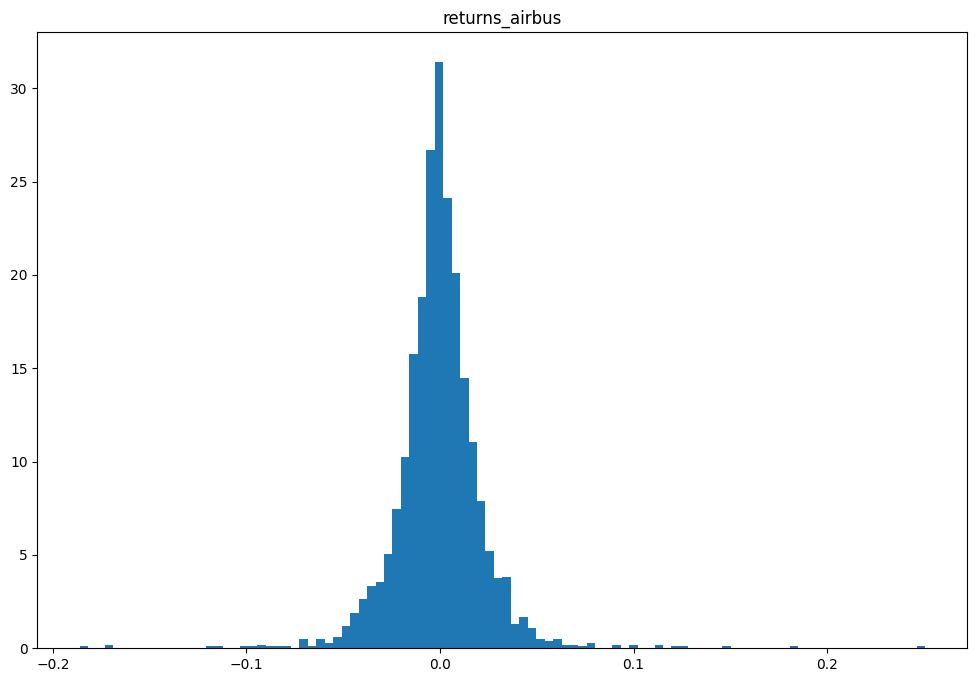

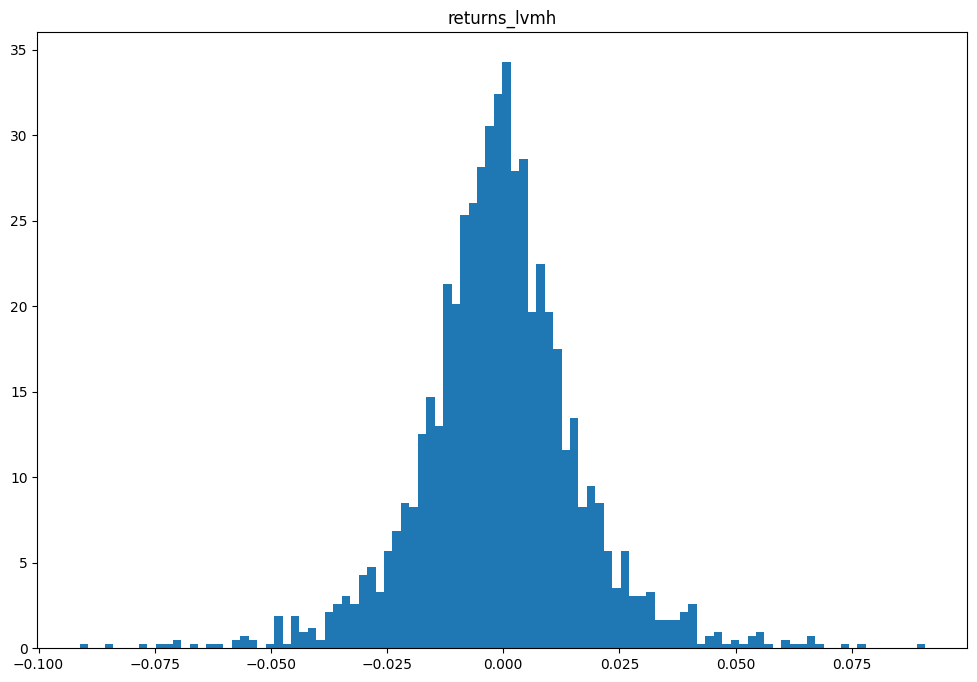

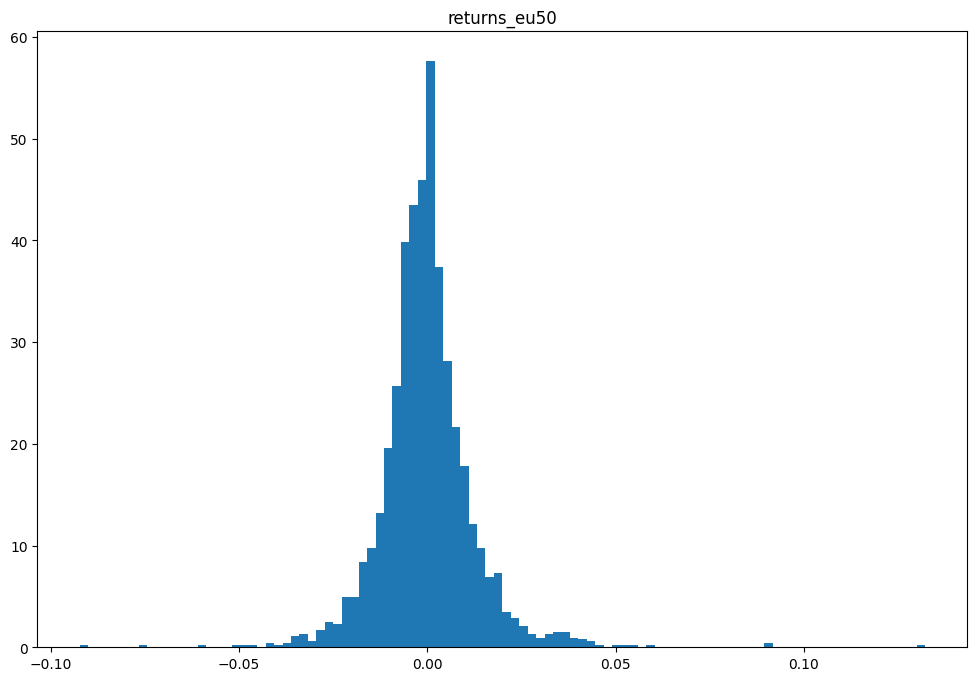

In [42]:
#Histogram of Asset Losses to see the Distribution outline
for i in range(N):
    plt.figure(figsize=(12, 8))
    plt.title(portfolio_df.columns[i])
    plt.hist(portfolio[:,i], bins=100, density=True)
    plt.show()

# SHOULD CORRECT FOR ZEROS GIVEN BY NON-TRADING DAYS
# PROBABLY USELESS PLOT ANYWAY

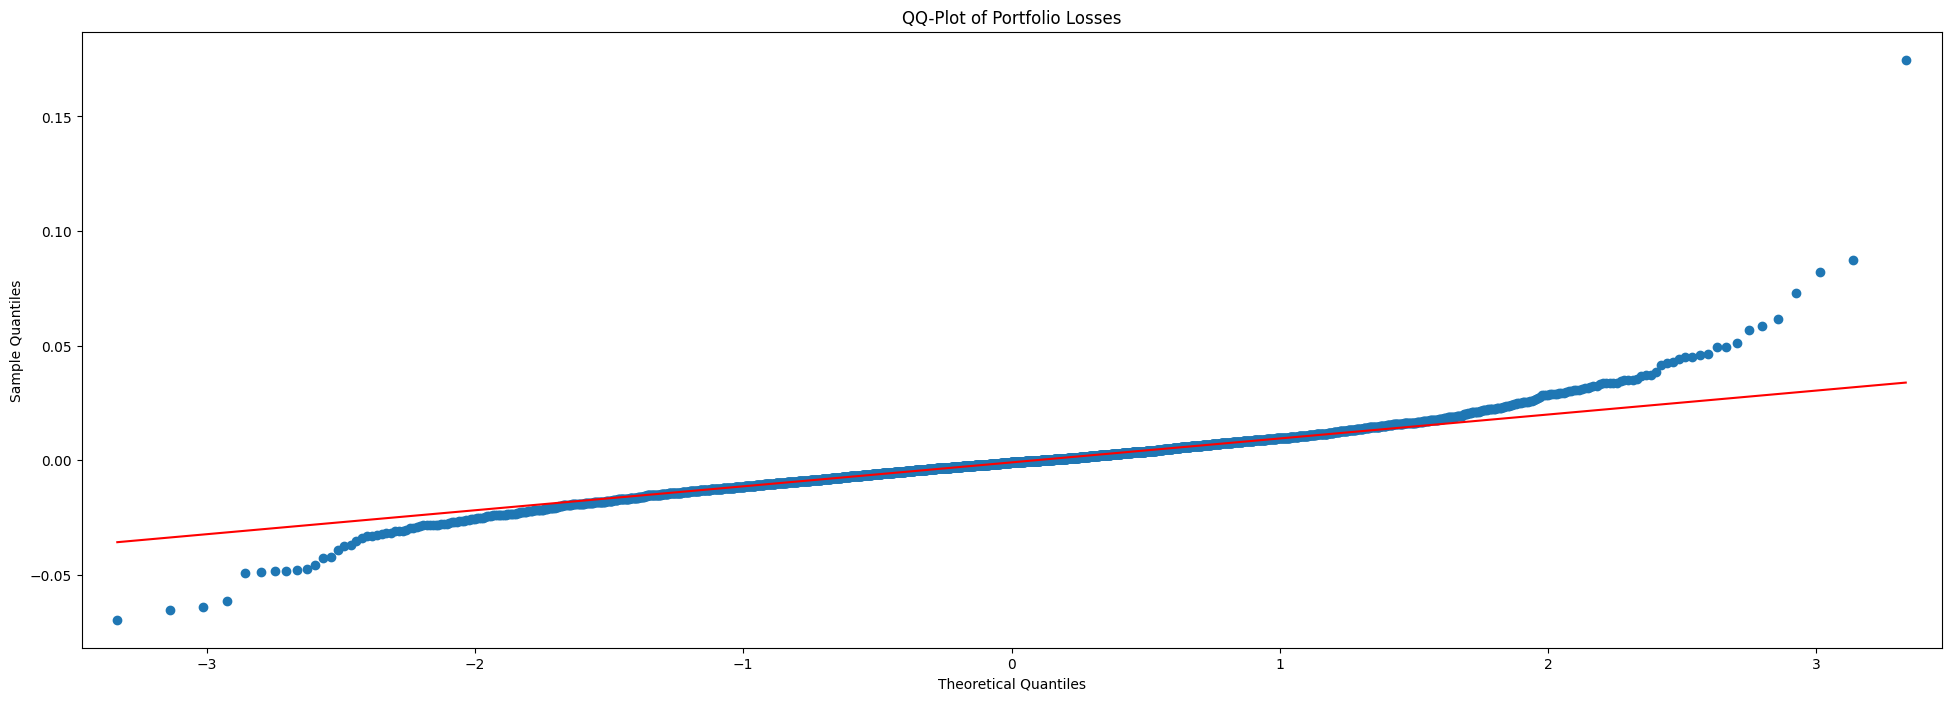

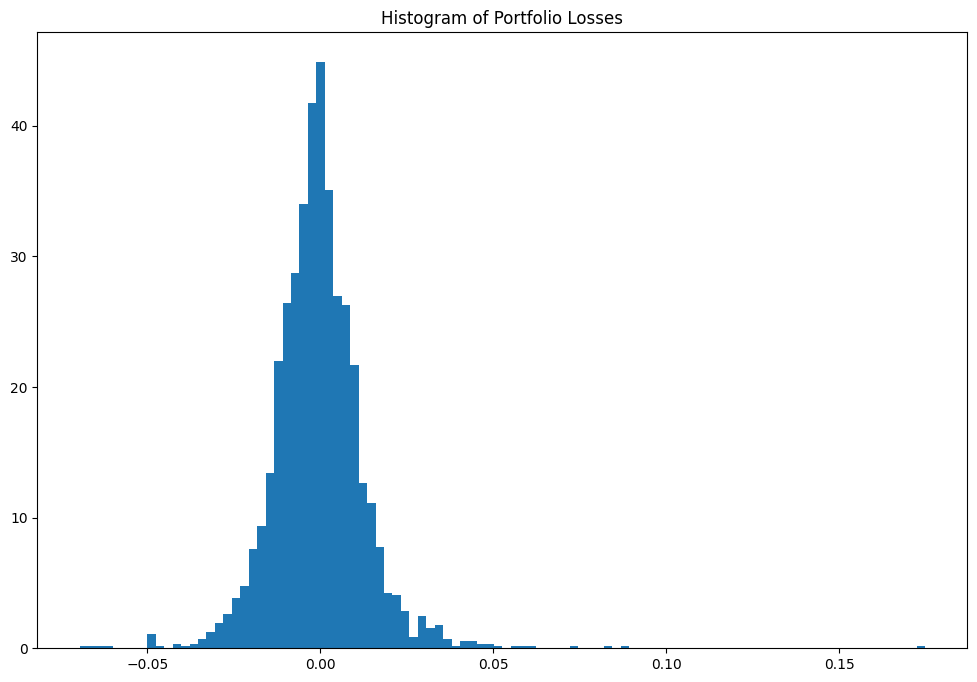

In [43]:
# Same but on Portfolio Level

#QQ-plot
sm.qqplot(portfolio_weighted, line='q')
plt.title("QQ-Plot of Portfolio Losses")

#Histogram
plt.figure(figsize=(12, 8))
plt.hist(portfolio_weighted, bins=100, density=True)
plt.title("Histogram of Portfolio Losses")
plt.show()

## t-Student Distribution Assumption

In [44]:
##Perform Student-t Var-Cov method
degrees_of_freedom = np.array([3, 4, 5, 6])
VarCovT_VaR_975 = np.zeros((T-ROLLING_WINDOW, len(degrees_of_freedom)))
VarCovT_VaR_99 = np.zeros((T-ROLLING_WINDOW, len(degrees_of_freedom)))
VarCovT_ES_975 = np.zeros((T-ROLLING_WINDOW, len(degrees_of_freedom)))
VarCovT_ES_99 = np.zeros((T-ROLLING_WINDOW, len(degrees_of_freedom)))
for i in range(T-ROLLING_WINDOW):
  (VarCovT_VaR_975[i,:], VarCovT_VaR_99[i,:], VarCovT_ES_975[i,:], VarCovT_ES_99[i,:])= calculate_portfolio_risk_metrics(PORTFOLIO_WEIGHTS, portfolio[i:ROLLING_WINDOW+i,:], "Student", degrees_of_freedom)

### Visualizing t-Student Distribution Assumption per each Asset in the Portfolio

/tmp/ipykernel_7875/1554675839.py:8: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  ax=plt.subplot(2,2,j))


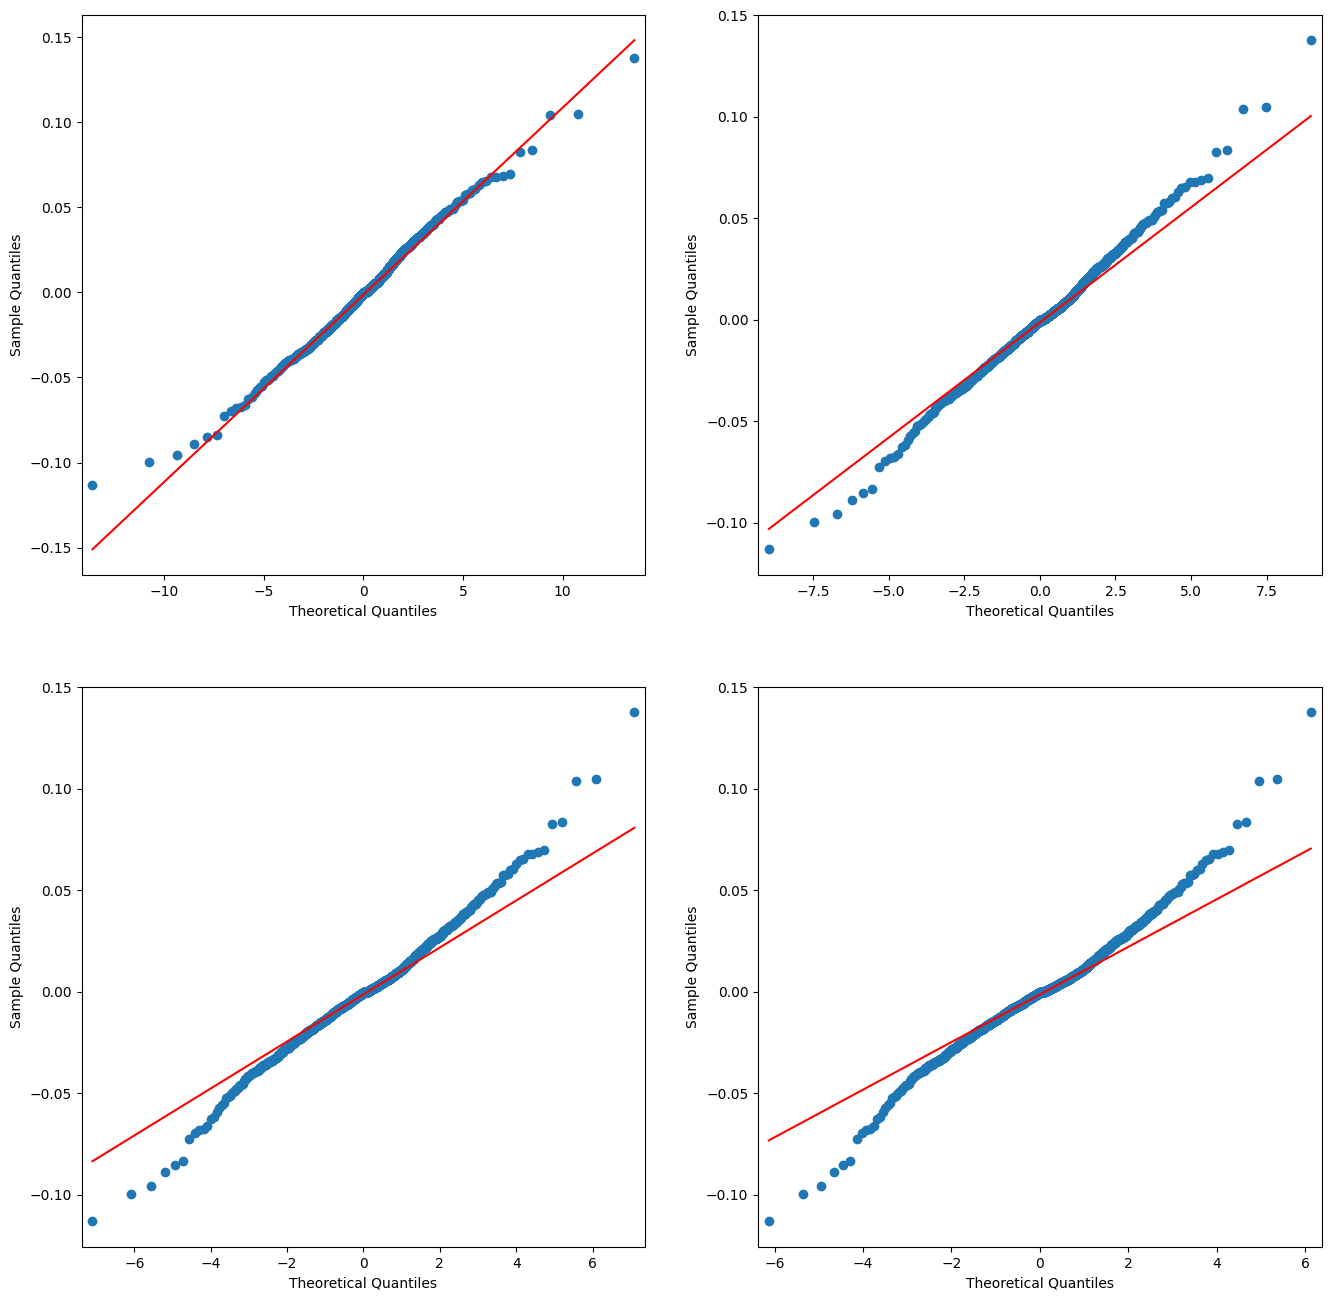

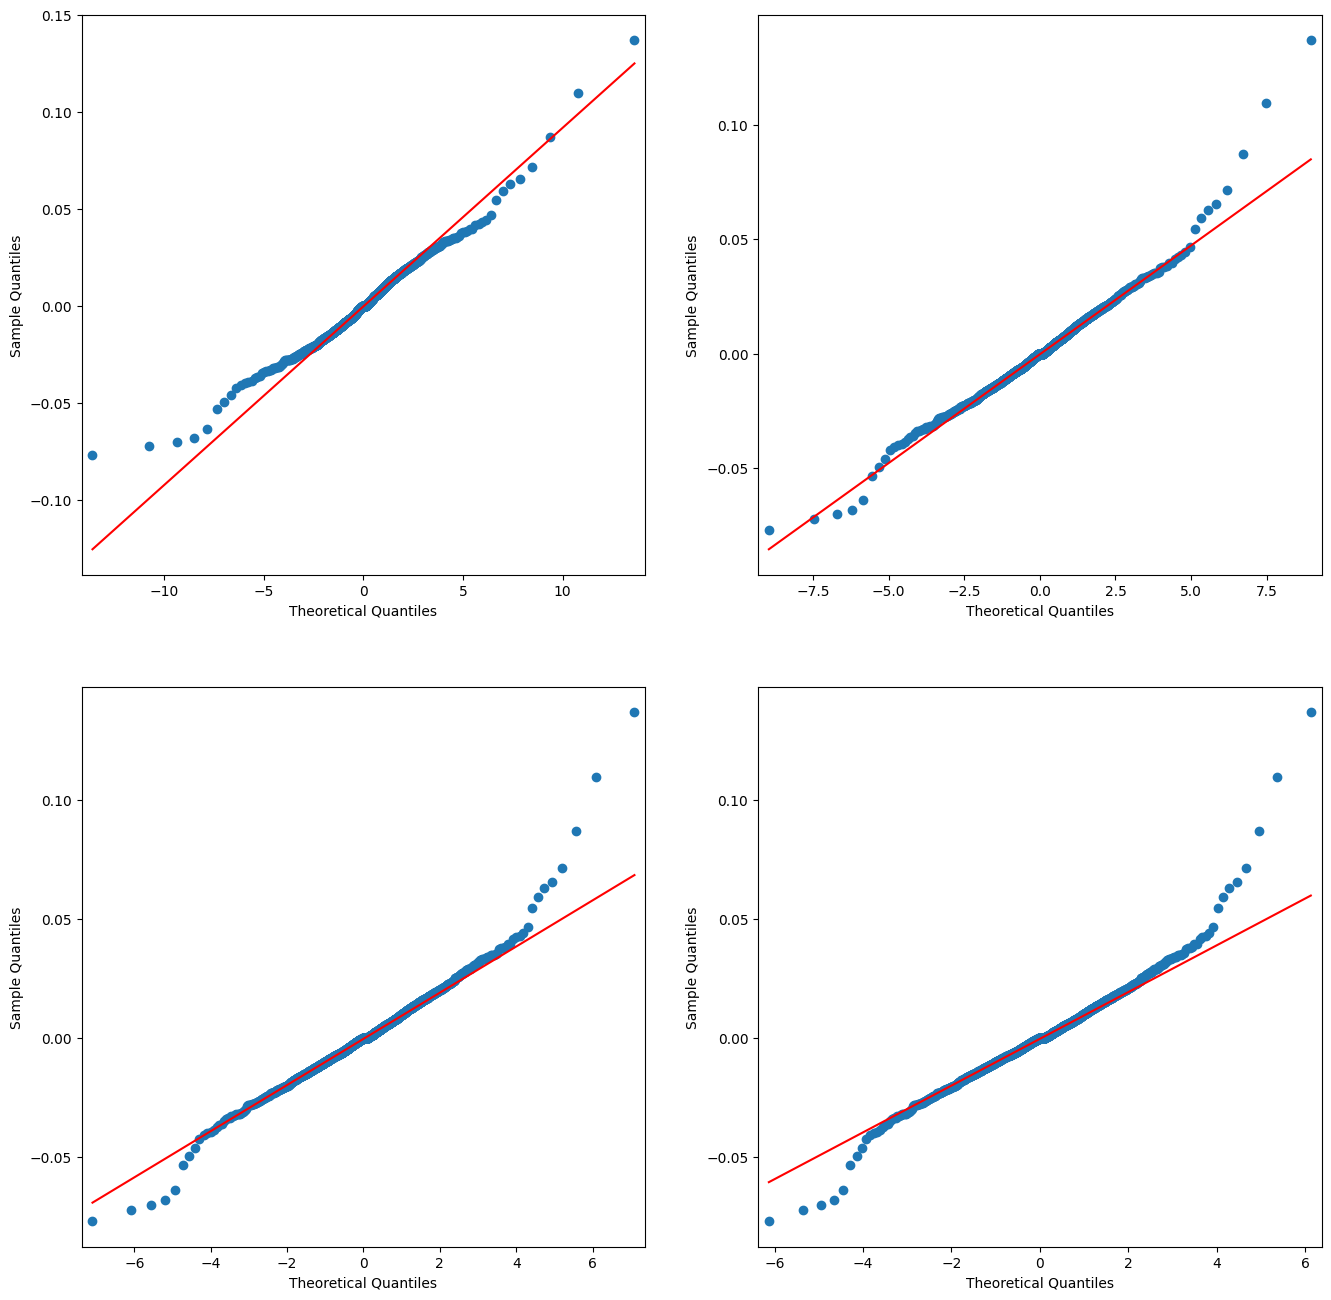

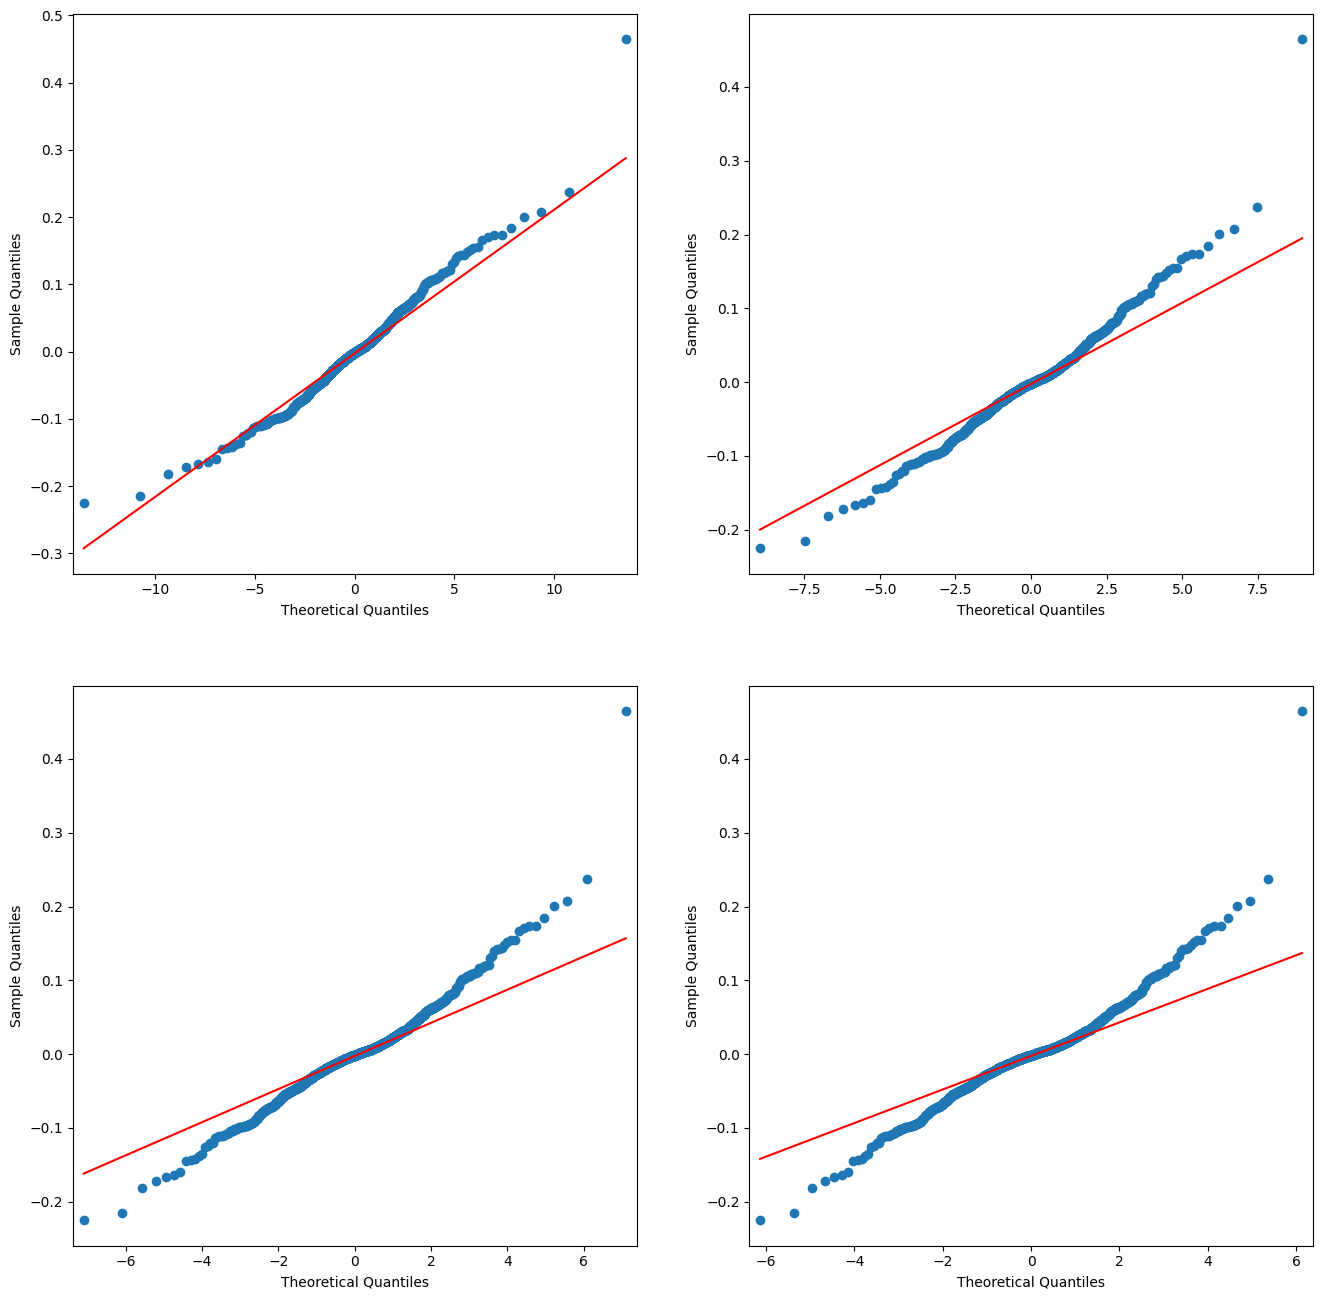

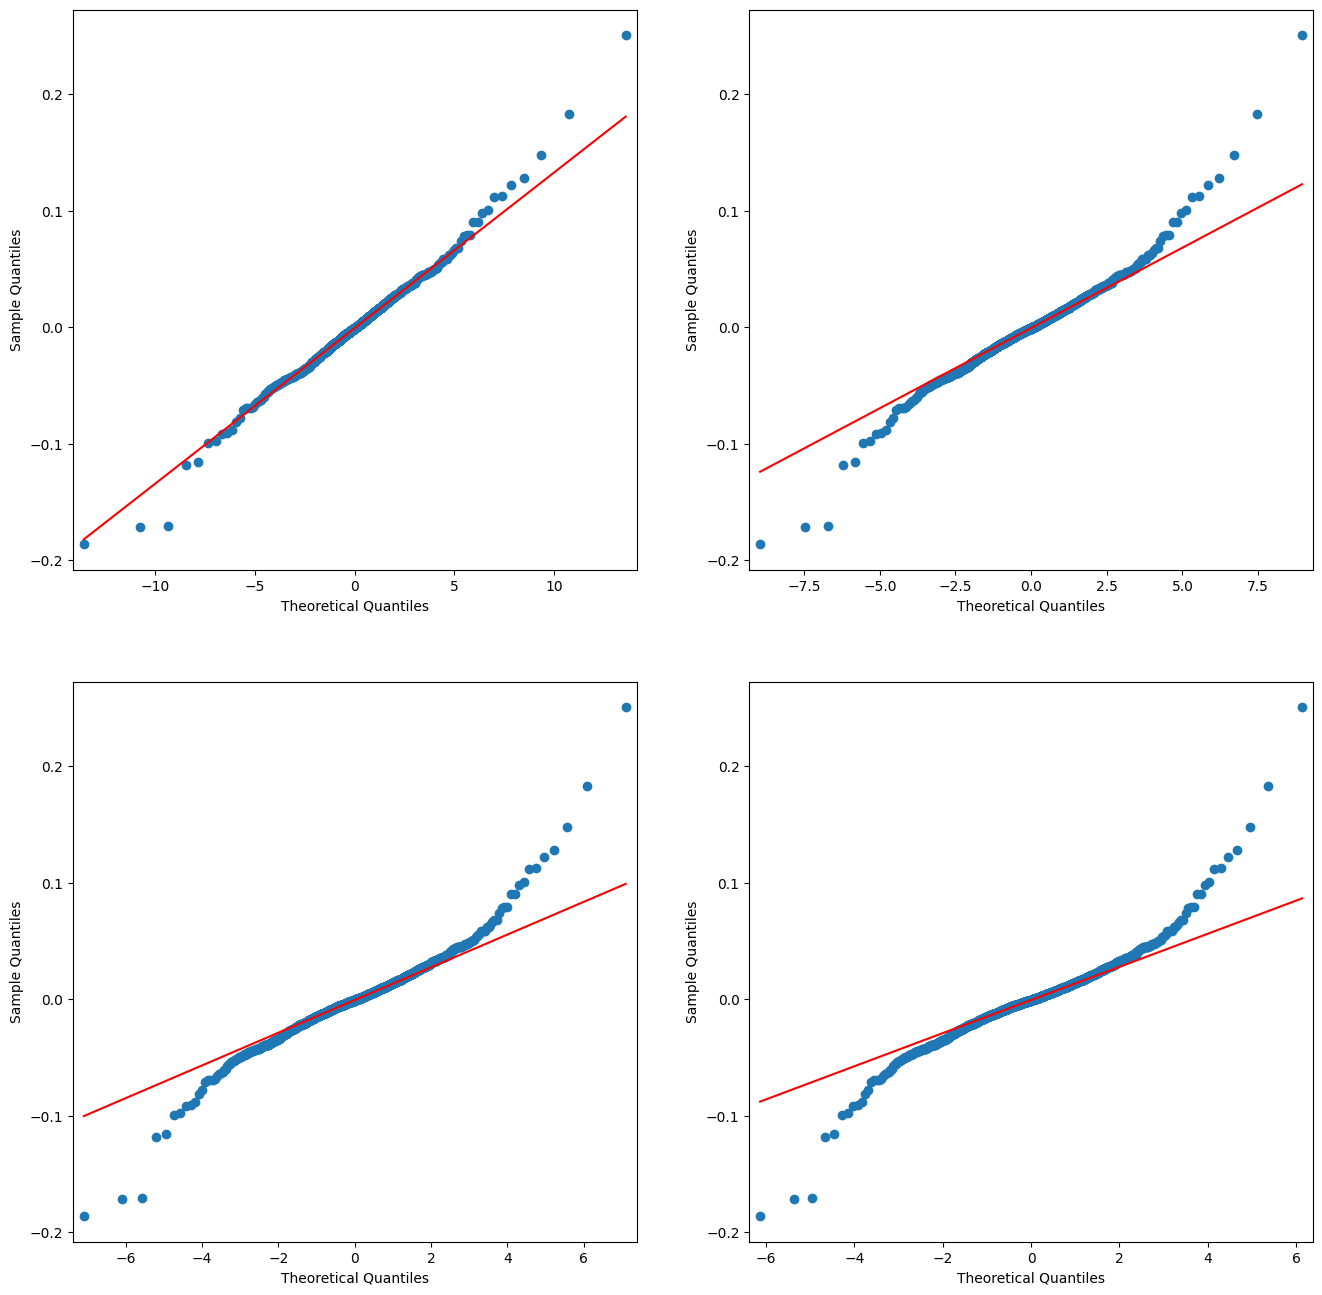

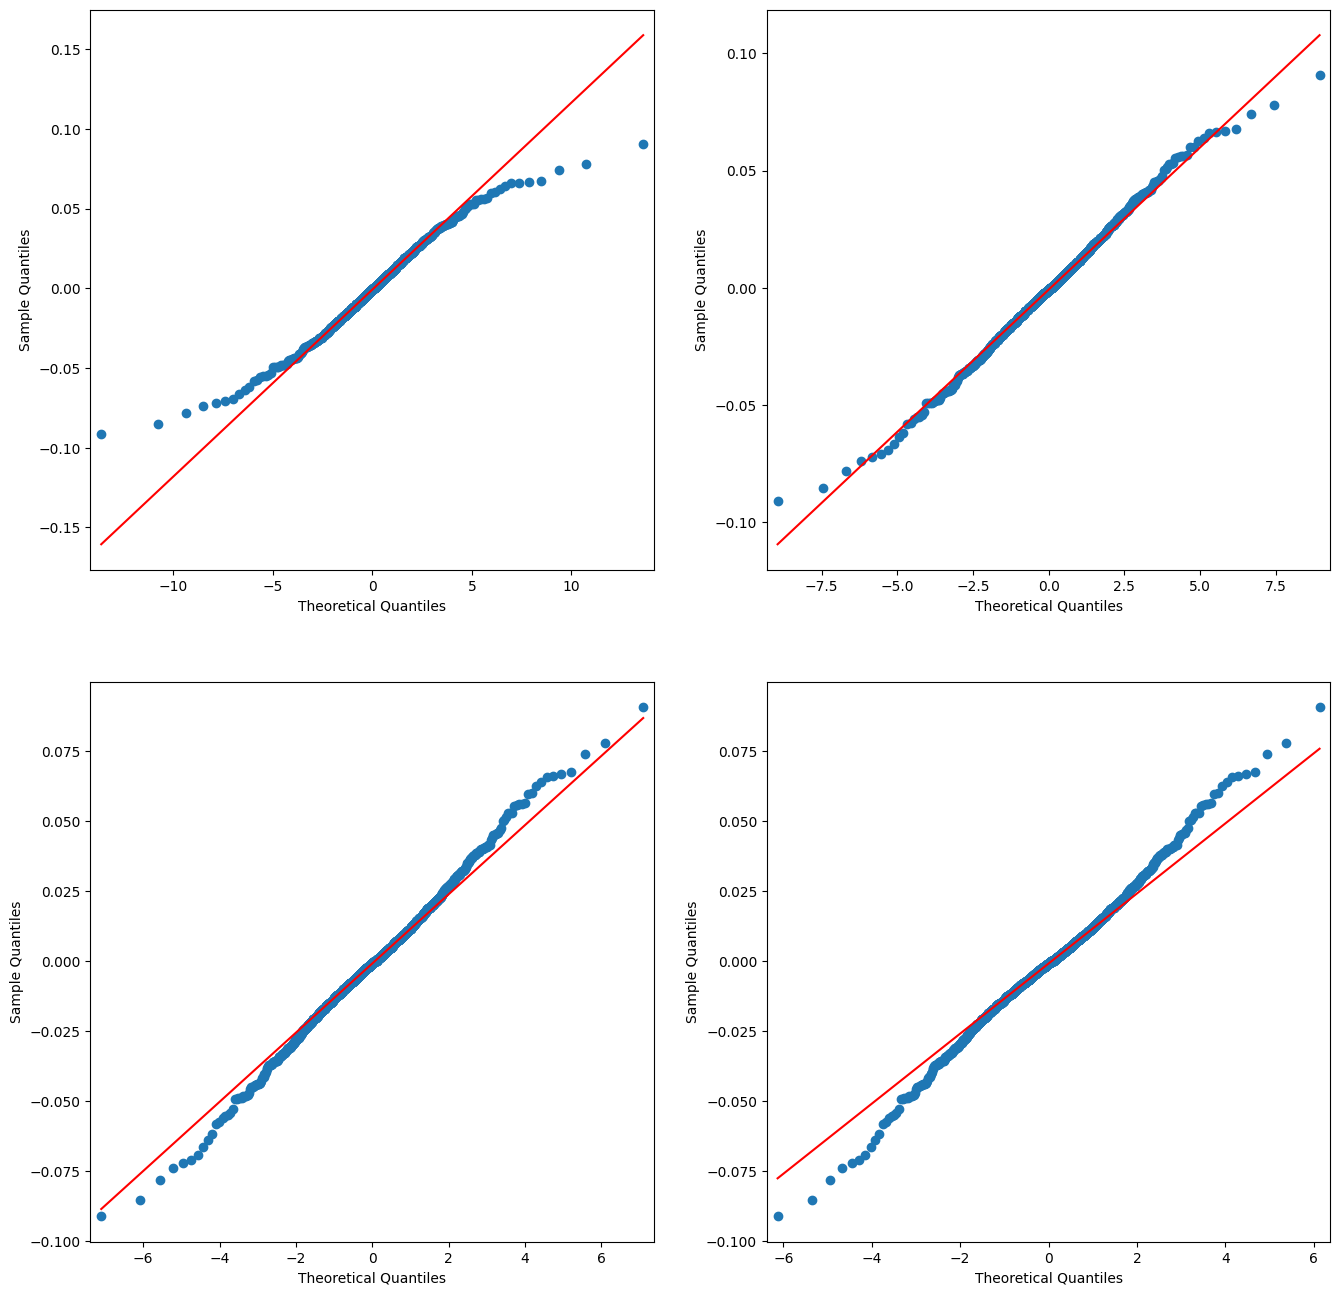

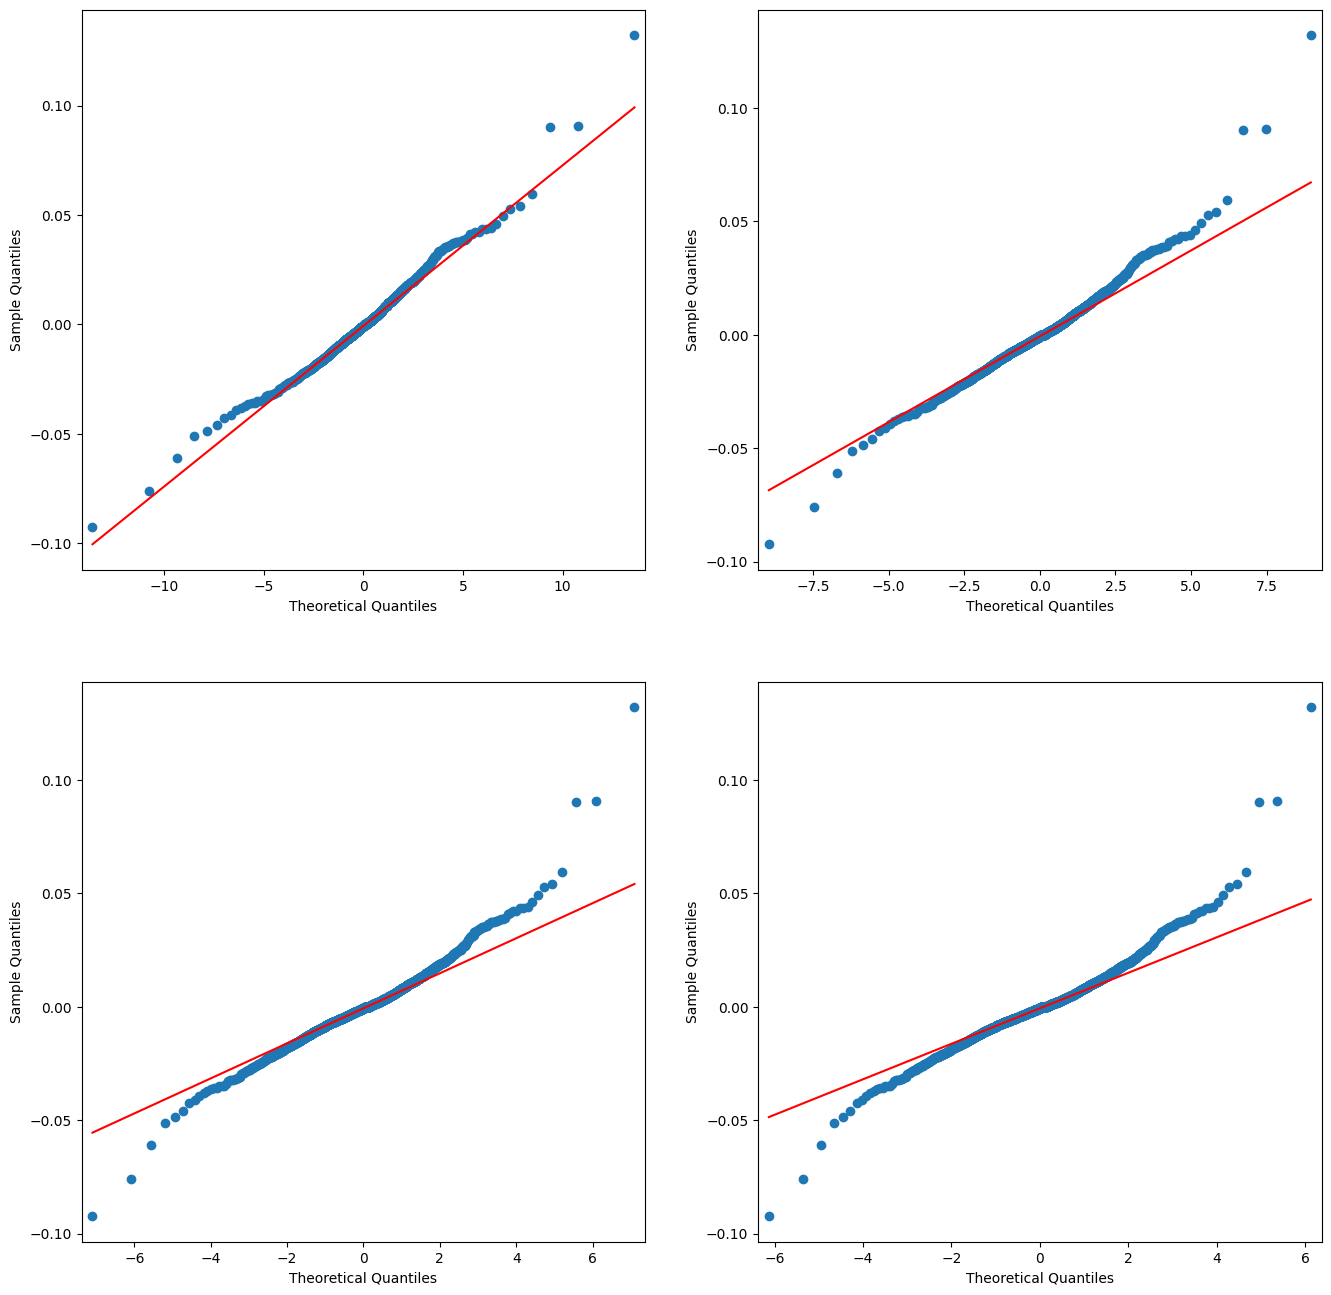

In [45]:
#QQ-plot of historical asset returns to assess validity of Student-t approximation
for i in range(N):
    j = 1
    plt.figure(figsize=(16,16))
    plt.title(portfolio_df.columns[i])
    for d in degrees_of_freedom:
        sm.qqplot(portfolio[:,i], dist=stats.t, distargs=(d,), line="q",
                  ax=plt.subplot(2,2,j))
        j += 1
    plt.show()

/tmp/ipykernel_7875/965713840.py:7: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  ax=plt.subplot(2,2,j))


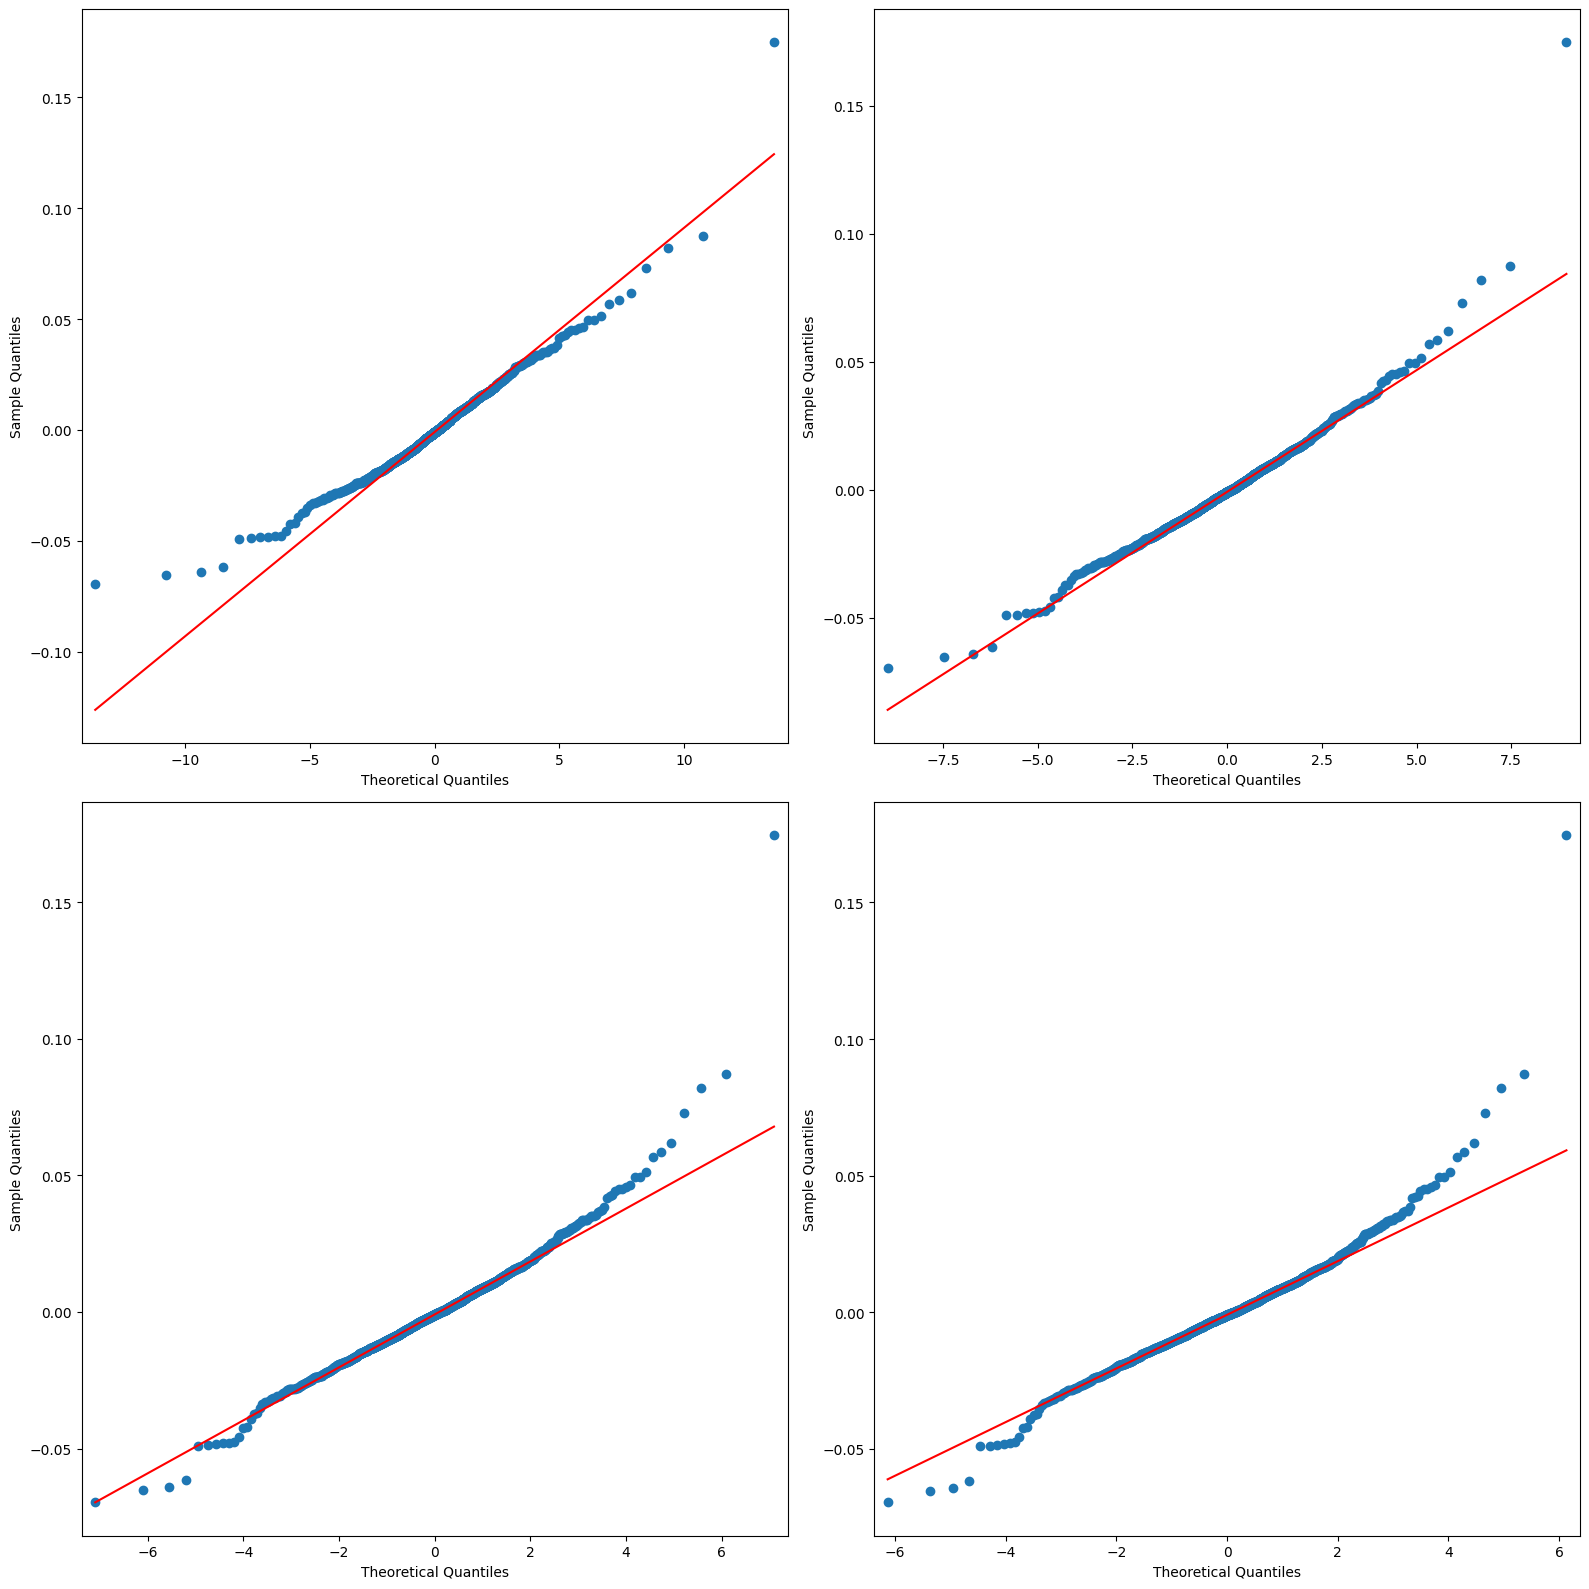

In [46]:
#QQ-plot of historical portfolio returns to assess validity of Student-t approximation
j = 1
plt.figure(figsize=(16,16))
plt.title("QQ-Plot Portfolio Losses")
for d in degrees_of_freedom:
    sm.qqplot(portfolio_weighted, dist=stats.t, distargs=(d,), line="q",
              ax=plt.subplot(2,2,j))
    plt.tight_layout()
    j += 1
plt.show()


### Conclusion: As can be seen t-Student with lowest degree fits data by far the best, because of the fattest tails

# Backtest

In [47]:
# DATES ARE DIFFERENT WITH YOUR APPROACH, IS IT BECAUSE OF THE WINDOW?
#dates = VaR_data_norm.index
dates = portfolio_df.index

# Not the best method, but works
indexes_where_year_changes = []
for i in range(len(dates)-1):
    if dates[i+1].year != dates[i].year:
        indexes_where_year_changes.append(i+1)
print(indexes_where_year_changes)

[258, 516, 774, 1032, 1290, 1549, 1808, 2066]


In [48]:
def Backtest(VaR_975, VaR_99, ES_975, ES_99, Loss):
    """
    Perform a t-test to assess the accuracy of the Expected Shortfall (ES) estimation at the confidence level.

    Parameters:
    - Loss: Array of observed losses.
    - VaR_975: Array of VaR estimates at the 97.5% confidence level.
    - ES_975: Array of ES estimates at the 97.5% confidence level.
    - VaR_99: Array of VaR estimates at the 99% confidence level.
    - ES_99: Array of ES estimates at the 99% confidence level.

    Returns:
    NO RETURNS FOR NOW
    - tTest_ES_975: The t-test statistic for the ES at the 97.5% level.
    - ES_p975: The p-value associated with the t-test.
    - T_99: The t-test statistic for the ES at the 97.5% level.
    - ES_p99: The p-value associated with the t-test.
    """
    print()
    # Convert gains into losses to align with the conventional risk metrics perspective
    Loss = -1 * Loss

    # .975 Level

    # Identify periods where the actual loss exceeds the VaR thresholds
    Violations_VaR_975 = Loss > VaR_975
    # Show amount of violations
    print("VaR Violations .975: ", sum(Violations_VaR_975))

    # Calculate the mean loss where there are VaR_975 violations
    average_Real_ES_975 = np.mean(Loss[Violations_VaR_975])
    # Adjust ES_975 estimates for comparison, using VaR_975 violations as the reference
    average_Theoretical_ES_975 = np.mean(ES_975[Violations_VaR_975])
    print("Average ES .975 Real and Theoretical: ", average_Real_ES_975, average_Theoretical_ES_975)

    # Calculate the standard error of losses exceeding the VaR_975
    standard_error = np.std(Loss[Violations_VaR_975]) / np.sqrt(np.sum(Violations_VaR_975))
    # Compute the t-test statistic
    tTest_ES_975 = (average_Real_ES_975 - average_Theoretical_ES_975) / standard_error
    # Calculate the two-sided p-value from the t-test statistic
    ES_p975 = stats.norm.sf(abs(tTest_ES_975)) * 2
    print("t-Test significance of difference: ", ES_p975)

    # .99 Level
    Violations_VaR_99 = Loss > VaR_99
    # Show amount of violations
    print("VaR Violations .99: ", sum(Violations_VaR_99))

    # Calculate the mean loss where there are VaR_99 violations
    average_Real_ES_99 = np.mean(Loss[Violations_VaR_99])
    # Adjust ES_99 estimates for comparison, using VaR_99 violations as the reference
    average_Theoretical_ES_99 = np.mean(ES_99[Violations_VaR_99])
    print("Average ES .99 Real and Theoretical: ", average_Real_ES_99, average_Theoretical_ES_99)

    # Calculate the standard error of losses exceeding the VaR_99
    standard_error = np.std(Loss[Violations_VaR_99]) / np.sqrt(np.sum(Violations_VaR_99))
    # Compute the t-test statistic
    tTest_ES_99 = (average_Real_ES_99 - average_Theoretical_ES_99) / standard_error
    # Calculate the two-sided p-value from the t-test statistic
    ES_p99 = stats.norm.sf(abs(tTest_ES_99)) * 2
    print("t-Test significance of difference: ", ES_p99)

    return


In [49]:
# Backtest VaR
index = indexes_where_year_changes

# For each period we find amount of VaR violations
for i in range(len(index)-1):
    print()
    print(f'Variance Covariance Normal | period={i}')
    Backtest(VarCovN_VaR_975[index[i]:index[i+1]], VarCovN_VaR_99[index[i]:index[i+1]],
              VarCovN_ES_975[index[i]:index[i+1]], VarCovN_ES_99[index[i]:index[i+1]],
              portfolio_weighted[index[i]:index[i+1]])
    
for i in range(len(index)-1):
    for j in range(len(degrees_of_freedom)):
        print()
        print(f'Variance Covariance t-Student | period={i}, dof={j+3}')
        Backtest(VarCovT_VaR_975[index[i]:index[i+1], j], VarCovT_VaR_99[index[i]:index[i+1], j],
                VarCovT_ES_975[index[i]:index[i+1], j], VarCovT_ES_99[index[i]:index[i+1], j],
                portfolio_weighted[index[i]:index[i+1]])


Variance Covariance Normal | period=0

VaR Violations .975:  14
Average ES .975 Real and Theoretical:  0.02059201181438081 0.019931900384647903
t-Test significance of difference:  0.528387176185652
VaR Violations .99:  7
Average ES .99 Real and Theoretical:  0.023626783780867106 0.022747955056993195
t-Test significance of difference:  0.49608312727805237

Variance Covariance Normal | period=1

VaR Violations .975:  8
Average ES .975 Real and Theoretical:  0.026730061665712155 0.02694147891143881
t-Test significance of difference:  0.8308340160970041
VaR Violations .99:  4
Average ES .99 Real and Theoretical:  0.02902648592784878 0.03076899373684603
t-Test significance of difference:  0.09594200178012409

Variance Covariance Normal | period=2

VaR Violations .975:  8
Average ES .975 Real and Theoretical:  0.0268873794016689 0.026185563774714565
t-Test significance of difference:  0.6557142447385873
VaR Violations .99:  4
Average ES .99 Real and Theoretical:  0.030316960567498354 0.0300

/tmp/ipykernel_7875/3551210729.py:58: RuntimeWarning: divide by zero encountered in scalar divide
  tTest_ES_99 = (average_Real_ES_99 - average_Theoretical_ES_99) / standard_error
